# Notebook 3A.03: Otimização pareada do XGBoost

## Carga instantânea versus trajetória operacional

Este notebook dá continuidade aos experimentos realizados nos Notebooks **3A**, **3A.01** e **3A.02**.

Os experimentos anteriores mostraram dois resultados principais.

Primeiro, a mudança da família de modelo de MLP para XGBoost produziu uma redução expressiva do erro de estimação das emissões horárias de CO₂.

Segundo, após a inclusão do controle A-XGBoost, observou-se que grande parte desse ganho também ocorre quando apenas a carga instantânea é utilizada.

Na validação temporal progressiva do Notebook 3A.02:

| Cenário | Features | MAE médio |
|---|---:|---:|
| A-XGBoost | 1 | 56,61 |
| B-XGBoost | 7 | 56,23 |
| C-XGBoost | 24 | 55,69 |

Assim, o ganho incremental da trajetória operacional foi pequeno diante da variabilidade observada entre os diferentes períodos.

O sanity check também confirmou:

- ausência de target leakage;
- construção correta das features;
- ausência de vazamento temporal;
- ausência de sobreposição entre treino, validação e holdout;
- utilização das mesmas observações na comparação entre MLP e XGBoost.

## Problema metodológico

Não seria adequado otimizar apenas o Cenário B.

Caso B recebesse um processo de tuning mais sofisticado que A, uma eventual melhora poderia resultar da otimização desigual, e não das informações de trajetória.

## Pergunta deste notebook

> **Após otimização controlada da mesma família de modelo, a inclusão de informações de trajetória operacional oferece ganho preditivo consistente em relação ao uso exclusivo da carga instantânea?**

## Cenários avaliados

### Cenário A

Apenas carga instantânea:

`CO₂(t) = f(P(t))`

Número de features: **1**

### Cenário B

Carga instantânea + trajetória operacional básica.

Número de features: **7**

O Cenário C não será otimizado nesta etapa.

A expansão de 7 para 24 features apresentou apenas pequeno ganho médio na validação temporal e pior resultado no holdout histórico, não justificando o aumento de complexidade nesta fase.

## Estratégia de otimização

Será utilizada uma busca aleatória controlada de hiperparâmetros.

As mesmas configurações candidatas serão avaliadas em A e B.

Serão explorados:

- número de árvores;
- learning rate;
- profundidade máxima;
- mínimo de observações efetivas por nó;
- fração de observações utilizada pelas árvores;
- fração de features utilizada pelas árvores;
- regularização L1;
- regularização L2;
- gamma.

## Validação temporal

Cada configuração será avaliada nos mesmos cinco folds temporais:

| Fold | Treino | Validação |
|---|---|---|
| 1 | janeiro a maio | junho |
| 2 | janeiro a junho | julho |
| 3 | janeiro a julho | agosto |
| 4 | janeiro a agosto | setembro |
| 5 | janeiro a setembro | outubro |

A métrica primária para seleção será:

**MAE médio dos cinco folds**

Como critérios secundários serão considerados:

1. RMSE médio;
2. desvio padrão do MAE entre folds.

## Holdout histórico

Novembro e dezembro não participarão da seleção dos hiperparâmetros.

Após a escolha da melhor configuração de A e da melhor configuração de B, os modelos serão reajustados utilizando todo o período de janeiro a outubro.

Somente então serão aplicados a novembro e dezembro.

Como esse período já foi observado em experimentos anteriores, ele será tratado como **holdout histórico de comparação**, e não como teste completamente cego.

## Interpretação

A comparação principal deste notebook será realizada na validação temporal.

Se B apresentar desempenho consistentemente melhor que A após ambos receberem o mesmo processo de otimização, haverá evidência mais forte de valor incremental das informações de trajetória.

Se A permanecer equivalente ou superior, o princípio de parcimônia favorecerá o modelo baseado apenas na carga instantânea.

### Verificação da aplicação dos métodos

As formulações das fontes foram confrontadas com as funções reais, os artefatos preservados e cálculos independentes. As verificações e seu alcance estão na [documentação técnica](../reproducibility/methods/README.md). Os resultados do experimento foram preservados. O período final ficou fora do ajuste dos modelos, mas sua consulta durante o desenvolvimento impede classificá-lo como avaliação globalmente cega. Os dados de origem são disponibilizados pela EPA/CAMPD (United States, 2026).


## Fundamentação, fontes e decisões do protocolo

As notas metodológicas vinculam as técnicas empregadas às respectivas publicações ou documentações oficiais. As referências completas aparecem ao final deste notebook. As rotinas de leitura, persistência, verificação de integridade e organização dos resultados são implementações do projeto.

**Escolhas do estudo.** O orçamento de 30 configurações, a semente, o espaço de busca e as cinco partições são escolhas do estudo. A comparação usa as mesmas configurações candidatas e observações, mas admite a seleção de configurações finais distintas para A e B. Não há teste formal de significância.

**Atualização documental de 24/10/2026.** Foram acrescentadas explicações, citações e referências. As instruções executáveis e as saídas armazenadas foram preservadas. Esta revisão não corresponde a uma nova execução dos experimentos. A rastreabilidade da verificação computacional permanece nos registros de reprodução.

O [guia de fundamentação metodológica](../docs/fundamentacao_metodologica.md) relaciona as fontes, seu alcance e os controles adotados ao longo dos notebooks.


In [37]:
# ============================================================
# CÉLULA 1: CONFIGURAÇÃO DO AMBIENTE
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Preparar o ambiente utilizado no Notebook 3A.03.
#
# Nesta célula:
#
#   1. importamos as bibliotecas;
#   2. configuramos a reprodutibilidade;
#   3. montamos o Google Drive;
#   4. definimos os diretórios do projeto;
#   5. localizamos os dados;
#   6. localizamos os resultados do Notebook 3A.02.
#
# Nenhum modelo é treinado nesta etapa.
# ============================================================


# ============================================================
# 1. IMPORTAÇÕES
# ============================================================

from google.colab import drive
from pathlib import Path

import json
import random
import warnings
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.model_selection import (
    ParameterSampler
)

import xgboost as xgb

from xgboost import (
    XGBRegressor
)

from IPython.display import (
    display,
    Markdown
)


# ============================================================
# 2. CONFIGURAÇÕES GERAIS
# ============================================================

warnings.filterwarnings(
    "ignore"
)


SEED = 42


random.seed(
    SEED
)


np.random.seed(
    SEED
)


# ============================================================
# 3. REGISTRAR A VERSÃO DO XGBOOST
# ============================================================
#
# Isso facilita a reprodução futura do experimento.
# ============================================================

print(
    "XGBoost:",
    xgb.__version__
)


# ============================================================
# 4. MONTAR O GOOGLE DRIVE
# ============================================================

drive.mount(
    "/content/drive"
)


# ============================================================
# 5. DIRETÓRIO PRINCIPAL
# ============================================================

ROOT = Path(
    "/content/drive/MyDrive/co2-cems-thermal-modeling"
)


DATA_INTERIM = (
    ROOT
    /
    "data"
    /
    "interim"
)


PIPELINE_DIR = (
    ROOT
    /
    "pipeline"
)


OUTPUT = (
    ROOT
    /
    "outputs"
)


REPORTS = (
    OUTPUT
    /
    "reports"
)


FIGURES = (
    OUTPUT
    /
    "figures"
)


TABLES = (
    OUTPUT
    /
    "tables"
)


MODELS = (
    OUTPUT
    /
    "models"
)


# ============================================================
# 6. GARANTIR AS PASTAS DE SAÍDA
# ============================================================

for folder in [

    REPORTS,
    FIGURES,
    TABLES,
    MODELS

]:

    folder.mkdir(
        parents=True,
        exist_ok=True
    )


# ============================================================
# 7. ARQUIVOS DE ENTRADA
# ============================================================

CONFIG_PATH = (
    PIPELINE_DIR
    /
    "selected_unit.json"
)


FULL_DATA_PATH = (
    DATA_INTERIM
    /
    "step05_feature_engineering.parquet"
)


# ============================================================
# 8. RESULTADOS DO NOTEBOOK 3A.02
# ============================================================
#
# Essas tabelas foram geradas depois do sanity check.
#
# Elas contêm:
#
#   resultados A, B e C na validação temporal;
#
#   resultados A, B e C no holdout histórico.
# ============================================================

BASELINE_CV_PATH = (
    TABLES
    /
    "03A02_cv_ABC_xgboost.csv"
)


BASELINE_HOLDOUT_PATH = (
    TABLES
    /
    "03A02_holdout_ABC_xgboost.csv"
)


print("=" * 72)

print(
    "NOTEBOOK 3A.03: OTIMIZAÇÃO PAREADA DO XGBOOST"
)

print("=" * 72)

print(
    "\nDiretório do projeto:"
)

print(
    ROOT
)

XGBoost: 3.4.1
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
NOTEBOOK 3A.03: OTIMIZAÇÃO PAREADA DO XGBOOST

Diretório do projeto:
/content/drive/MyDrive/co2-cems-thermal-modeling


In [38]:
# ============================================================
# CÉLULA 2: CARREGAMENTO DOS DADOS E DOS BASELINES
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Recuperar:
#
#   1. a identificação da unidade;
#   2. a série horária completa;
#   3. os resultados A/B/C anteriores.
#
#
# IMPORTANTE
# ------------------------------------------------------------
# O Notebook 3A.03 não utilizará os resultados do holdout para
# selecionar hiperparâmetros.
#
# Eles são carregados apenas para comparação posterior.
# ============================================================


# ============================================================
# 1. VERIFICAR ARQUIVOS
# ============================================================

required_files = [

    CONFIG_PATH,

    FULL_DATA_PATH,

    BASELINE_CV_PATH,

    BASELINE_HOLDOUT_PATH

]


for file_path in required_files:

    if not file_path.exists():

        raise FileNotFoundError(

            f"Arquivo necessário não encontrado: {file_path}\n"

            "Confirme se a Célula 21 atualizada do Notebook "
            "3A.02 foi executada."

        )


# ============================================================
# 2. IDENTIFICAÇÃO DA UNIDADE
# ============================================================

with open(
    CONFIG_PATH,
    "r",
    encoding="utf-8"
) as f:

    selected_unit = json.load(
        f
    )


# ============================================================
# 3. SÉRIE HORÁRIA
# ============================================================

df = pd.read_parquet(
    FULL_DATA_PATH
)


df[
    "timestamp"
] = pd.to_datetime(

    df[
        "timestamp"
    ]

)


df = (

    df

    .sort_values(
        "timestamp"
    )

    .reset_index(
        drop=True
    )

)


# ============================================================
# 4. RESULTADOS DO NOTEBOOK 3A.02
# ============================================================

baseline_cv = pd.read_csv(
    BASELINE_CV_PATH
)


baseline_holdout = pd.read_csv(
    BASELINE_HOLDOUT_PATH
)


# ============================================================
# 5. CONFERÊNCIA
# ============================================================

print("=" * 72)
print("DADOS CARREGADOS")
print("=" * 72)


print(

    f"\nUnidade: "
    f"{selected_unit['facility_name']} "
    f"Unit {selected_unit['unit_id']}"

)


print(
    "Facility ID:",
    selected_unit["facility_id"]
)


print(
    "Ano:",
    selected_unit["year"]
)


print(
    "\nRegistros horários:",
    f"{len(df):,}"
)


print(
    "\nBaseline da validação temporal:"
)


display(
    baseline_cv.round(4)
)


print(
    "\nBaseline do holdout histórico:"
)


display(
    baseline_holdout.round(4)
)

DADOS CARREGADOS

Unidade: Iatan Unit 2
Facility ID: 6065
Ano: 2025

Registros horários: 8,760

Baseline da validação temporal:


,cenario,MAE_mean,MAE_std,RMSE_mean,RMSE_std,R2_mean,R2_std
0,A,56.6132,17.3006,72.1941,14.9393,0.8582,0.0623
1,B,56.2298,17.0684,71.8576,14.0435,0.8591,0.0606
2,C,55.6889,17.2915,71.0960,14.3441,0.8623,0.0598



Baseline do holdout histórico:


,cenario,n_features,MAE,RMSE,R2
0,A-XGBoost,1,22.9625,28.0571,0.9809
1,B-XGBoost,7,23.2657,28.8090,0.9798
2,C-XGBoost,24,25.0194,30.6338,0.9772


In [39]:
# ============================================================
# CÉLULA 3: DEFINIÇÃO DOS CENÁRIOS A E B
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Reconstruir exatamente os dois conjuntos de informações que
# serão submetidos ao mesmo processo de otimização.
#
#
# Cenário A:
#
#       apenas carga instantânea
#
#
# Cenário B:
#
#       carga + trajetória operacional básica
#
#
# Nenhuma nova feature será criada neste notebook.
# ============================================================


TARGET = (
    "CO2 Mass (short tons)"
)


# ============================================================
# 1. CENÁRIO A
# ============================================================

FEATURES_A = [

    "load_current_mw"

]


# ============================================================
# 2. CENÁRIO B
# ============================================================

FEATURES_B = [

    "load_current_mw",

    "load_lag_1h",

    "delta_load_1h",

    "abs_delta_load_1h",

    "load_mean_previous_3h",

    "operating_time_lag_1h",

    "hours_since_startup"

]


# ============================================================
# 3. COLUNAS NECESSÁRIAS
# ============================================================

required_columns = [

    "timestamp",

    "is_on",

    TARGET

] + FEATURES_B


# ============================================================
# 4. BASE EXPERIMENTAL
# ============================================================
#
# Para garantir comparação pareada, A e B utilizarão exatamente
# as mesmas observações.
#
# Portanto, a base é construída exigindo disponibilidade de
# todas as features de B, mesmo que A utilize apenas uma.
# ============================================================

experiment_data = (

    df.loc[

        df[
            "is_on"
        ],

        required_columns

    ]

    .dropna()

    .sort_values(
        "timestamp"
    )

    .reset_index(
        drop=True
    )

)


# ============================================================
# 5. CONFERÊNCIA
# ============================================================

scenario_table = pd.DataFrame({

    "cenario": [

        "A: carga instantânea",

        "B: trajetória básica"

    ],

    "n_features": [

        len(
            FEATURES_A
        ),

        len(
            FEATURES_B
        )

    ]

})


display(
    scenario_table
)


print(
    "\nObservações disponíveis:",
    len(
        experiment_data
    )
)


print(
    "Período:",
    experiment_data[
        "timestamp"
    ].min(),
    "→",
    experiment_data[
        "timestamp"
    ].max()
)

,cenario,n_features
0,A: carga instantânea,1
1,B: trajetória básica,7



Observações disponíveis: 6249
Período: 2025-01-01 16:00:00 → 2025-12-31 23:00:00


### Validação temporal *walk-forward* com janela expansiva

A divisão descrita a seguir é uma **walk-forward temporal cross-validation with an expanding training window** (validação cruzada temporal progressiva com janela expansiva). O início do treinamento permanece em janeiro, enquanto o final da janela se desloca de maio a setembro; a validação ocorre sempre no mês imediatamente seguinte (junho a outubro).

Esse desenho respeita a ordem cronológica e não deve ser confundido com *KFold* aleatório. Os cinco folds são idênticos para A e B, permitindo examinar a estabilidade da diferença de MAE entre os períodos.

### Fontes da avaliação temporal

A avaliação de modelos para séries temporais precisa considerar a ordem das observações e o procedimento de estimação do desempenho (Cerqueira; Torgo; Mozetič, 2020). Neste estudo, as datas das partições e o calendário das validações são decisões do protocolo. O teste permanece fora do ajuste de cada comparação, mas seu uso reiterado no desenvolvimento limita a independência da avaliação em relação às decisões da pesquisa (Cawley; Talbot, 2010). A divisão cronológica, isoladamente, não elimina esse limite.


In [40]:
# Referências metodológicas: (Cerqueira; Torgo; Mozetič, 2020; Cawley; Talbot, 2010).
# Escopo e decisões próprias estão na nota imediatamente anterior; referências completas ao final.
# ============================================================
# CÉLULA 4: DEFINIÇÃO DA VALIDAÇÃO TEMPORAL
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Reproduzir os mesmos cinco folds temporais utilizados no
# Notebook 3A.02.
#
# Cada modelo é treinado somente com observações anteriores ao
# período utilizado para validação.
#
# Nenhuma divisão aleatória será realizada.
#
# FUNDAMENTAÇÃO METODOLÓGICA
# ------------------------------------------------------------
# Walk-forward temporal cross-validation with expanding window:
# em cada fold, o início do treino é mantido e sua data final
# avança, enquanto a validação ocorre no mês seguinte.
# Trata-se de validação temporal com janela de treino expansiva,
# não de KFold aleatório, preservando a ordem cronológica.
# Os mesmos folds serão aplicados a A e B.

# ============================================================


YEAR = int(
    selected_unit[
        "year"
    ]
)


FOLDS = [

    {

        "fold":
            1,

        "train_end":
            f"{YEAR}-05-31 23:00:00",

        "val_start":
            f"{YEAR}-06-01 00:00:00",

        "val_end":
            f"{YEAR}-06-30 23:00:00"

    },

    {

        "fold":
            2,

        "train_end":
            f"{YEAR}-06-30 23:00:00",

        "val_start":
            f"{YEAR}-07-01 00:00:00",

        "val_end":
            f"{YEAR}-07-31 23:00:00"

    },

    {

        "fold":
            3,

        "train_end":
            f"{YEAR}-07-31 23:00:00",

        "val_start":
            f"{YEAR}-08-01 00:00:00",

        "val_end":
            f"{YEAR}-08-31 23:00:00"

    },

    {

        "fold":
            4,

        "train_end":
            f"{YEAR}-08-31 23:00:00",

        "val_start":
            f"{YEAR}-09-01 00:00:00",

        "val_end":
            f"{YEAR}-09-30 23:00:00"

    },

    {

        "fold":
            5,

        "train_end":
            f"{YEAR}-09-30 23:00:00",

        "val_start":
            f"{YEAR}-10-01 00:00:00",

        "val_end":
            f"{YEAR}-10-31 23:00:00"

    }

]


fold_table = pd.DataFrame(
    FOLDS
)


display(
    fold_table
)

,fold,train_end,val_start,val_end
0,1,2025-05-31 23:00:00,2025-06-01 00:00:00,2025-06-30 23:00:00
1,2,2025-06-30 23:00:00,2025-07-01 00:00:00,2025-07-31 23:00:00
2,3,2025-07-31 23:00:00,2025-08-01 00:00:00,2025-08-31 23:00:00
3,4,2025-08-31 23:00:00,2025-09-01 00:00:00,2025-09-30 23:00:00
4,5,2025-09-30 23:00:00,2025-10-01 00:00:00,2025-10-31 23:00:00


### Busca aleatória de hiperparâmetros (*Random Search*)

A otimização utiliza **Random Search**, implementada pelo `ParameterSampler` do scikit-learn, para selecionar 30 configurações candidatas do espaço especificado. O parâmetro `random_state=SEED` fixa o sorteio das configurações, favorecendo a reprodutibilidade. Isso difere de *Grid Search*, que percorreria todas as combinações de uma grade definida.

Cada configuração é testada nos **dois cenários e nos cinco folds**, totalizando 300 ajustes. Neste protocolo, `n_estimators` é um dos hiperparâmetros avaliados. **Não é utilizado early stopping na etapa de busca:** o mês de validação é reservado para avaliar o desempenho de cada configuração.

### Origem da busca aleatória e do estimador

A busca aleatória de hiperparâmetros é fundamentada por Bergstra e Bengio (2012). O ParameterSampler implementa o sorteio conforme a documentação da biblioteca (Scikit-learn, 2025). Os 30 candidatos e os limites dos hiperparâmetros são escolhas do estudo, não valores prescritos pelo artigo. Nesta busca, n_estimators integra o espaço avaliado e não há early stopping.

O fundamento de gradient boosting é apresentado por Friedman (2001). O algoritmo XGBoost e sua formulação regularizada são descritos por Chen e Guestrin (2016). Os valores dos hiperparâmetros e o critério de seleção do número de árvores são escolhas do protocolo explicitadas na célula. As fontes não são apresentadas como prescrição desses valores específicos.


In [41]:
# Referências metodológicas: (Bergstra; Bengio, 2012; Scikit-learn, 2025; Friedman, 2001; Chen; Guestrin, 2016).
# Escopo e decisões próprias estão na nota imediatamente anterior; referências completas ao final.
# ============================================================
# CÉLULA 5: ESPAÇO DE BUSCA DOS HIPERPARÂMETROS
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Definir quais configurações do XGBoost serão exploradas.
#
#
# ESTRATÉGIA
# ------------------------------------------------------------
# Será utilizado ParameterSampler para sortear um conjunto
# reproduzível de configurações.
#
# O procedimento é uma RANDOM SEARCH (busca aleatória de
# hiperparâmetros). O ParameterSampler amostra 30 combinações
# do espaço definido, com random_state=SEED para reproduzir
# o sorteio das configurações em novas execuções.
# Diferentemente de Grid Search, o experimento não enumera
# exaustivamente todas as combinações possíveis.

#
# A MESMA lista de configurações será aplicada aos Cenários
# A e B.
#
# Isso garante igualdade de oportunidade na otimização.
#
#
# IMPORTANTE
# ------------------------------------------------------------
# Nesta etapa NÃO utilizamos EarlyStopping.
#
# O número de árvores é tratado explicitamente como um
# hiperparâmetro.
#
# Assim, o mês utilizado para validar um fold serve somente
# para avaliar a configuração e não interfere no treinamento
# daquele modelo.
# ============================================================


# ============================================================
# 1. QUANTIDADE DE CONFIGURAÇÕES
# ============================================================
#
# 30 configurações x 2 cenários x 5 folds
#
#       = 300 treinamentos
#
# Foram fixadas 30 configurações como orçamento computacional
# desta etapa. Não foi demonstrado que esse orçamento esgota
# o espaço de busca ou garante a melhor configuração possível.
# ============================================================

N_CONFIGS = 30


# ============================================================
# 2. ESPAÇO DE BUSCA
# ============================================================

SEARCH_SPACE = {


    # --------------------------------------------------------
    # Quantidade de árvores do ensemble.
    # --------------------------------------------------------

    "n_estimators": [

        200,
        400,
        600,
        800,
        1200

    ],


    # --------------------------------------------------------
    # Taxa de aprendizado.
    #
    # Valores menores produzem atualizações mais conservadoras,
    # normalmente exigindo maior número de árvores.
    # --------------------------------------------------------

    "learning_rate": [

        0.01,
        0.02,
        0.03,
        0.05,
        0.08

    ],


    # --------------------------------------------------------
    # Complexidade máxima de cada árvore.
    # --------------------------------------------------------

    "max_depth": [

        2,
        3,
        4,
        5,
        6

    ],


    # --------------------------------------------------------
    # Restrição para criação de novos nós.
    #
    # Valores maiores tornam as árvores mais conservadoras.
    # --------------------------------------------------------

    "min_child_weight": [

        1,
        3,
        5,
        8,
        12

    ],


    # --------------------------------------------------------
    # Fração das observações utilizada para cada árvore.
    # --------------------------------------------------------

    "subsample": [

        0.65,
        0.75,
        0.85,
        1.00

    ],


    # --------------------------------------------------------
    # Fração das features considerada por árvore.
    # --------------------------------------------------------

    "colsample_bytree": [

        0.65,
        0.75,
        0.85,
        1.00

    ],


    # --------------------------------------------------------
    # Regularização L1.
    # --------------------------------------------------------

    "reg_alpha": [

        0.0,
        0.01,
        0.10,
        0.50,
        1.00

    ],


    # --------------------------------------------------------
    # Regularização L2.
    # --------------------------------------------------------

    "reg_lambda": [

        0.50,
        1.00,
        2.00,
        5.00,
        10.00

    ],


    # --------------------------------------------------------
    # Redução mínima necessária na função objetivo para permitir
    # uma nova divisão na árvore.
    # --------------------------------------------------------

    "gamma": [

        0.00,
        0.05,
        0.10,
        0.25,
        0.50

    ]

}


# ============================================================
# 3. SORTEAR AS CONFIGURAÇÕES
# ============================================================

sampled_configs = list(

    ParameterSampler(

        SEARCH_SPACE,

        n_iter=N_CONFIGS,

        random_state=SEED

    )

)


# ============================================================
# 4. ATRIBUIR IDENTIFICADORES
# ============================================================

config_ids = [

    f"CFG_{i:02d}"

    for i in range(
        1,
        len(sampled_configs) + 1
    )

]


config_lookup = {

    config_id:
        config

    for (
        config_id,
        config
    ) in zip(

        config_ids,

        sampled_configs

    )

}


# ============================================================
# 5. TABELA DAS CONFIGURAÇÕES
# ============================================================

configs_table = pd.DataFrame(
    sampled_configs
)


configs_table.insert(
    0,
    "config_id",
    config_ids
)


print(
    "Configurações sorteadas:",
    len(
        configs_table
    )
)


display(
    configs_table.head(10)
)

Configurações sorteadas: 30


,config_id,subsample,reg_lambda,reg_alpha,n_estimators,min_child_weight,max_depth,learning_rate,gamma,colsample_bytree
0,CFG_01,0.85,10.0,0.10,1200,8,5,0.08,0.05,0.65
1,CFG_02,1.00,5.0,0.10,400,5,5,0.05,0.00,0.85
2,CFG_03,0.65,5.0,0.01,1200,8,4,0.01,0.10,0.65
3,CFG_04,0.85,10.0,0.50,400,8,5,0.01,0.50,0.65
4,CFG_05,0.65,2.0,0.50,600,1,6,0.05,0.05,0.65
5,CFG_06,0.65,0.5,1.00,400,12,4,0.05,0.05,0.85
6,CFG_07,0.85,0.5,0.50,1200,3,3,0.05,0.10,1.00
7,CFG_08,0.75,10.0,0.01,800,12,6,0.01,0.10,0.65
8,CFG_09,0.85,2.0,1.00,800,12,6,0.08,0.00,1.00
9,CFG_10,0.85,5.0,0.50,200,5,6,0.01,0.25,1.00


### Fontes da avaliação de erros

MAE e RMSE pertencem às medidas usuais de magnitude do erro discutidas por Hyndman e Koehler (2006). As funções de regressão da biblioteca, incluindo R², estão documentadas no guia da biblioteca (Scikit-learn, 2025). As métricas são calculadas sobre as mesmas observações usadas na comparação indicada em cada etapa. A análise dos pares é descritiva e não equivale a um teste de significância.


In [42]:
# Referências metodológicas: (Hyndman; Koehler, 2006; Scikit-learn, 2025).
# Escopo e decisões próprias estão na nota imediatamente anterior; referências completas ao final.
# ============================================================
# CÉLULA 6: FUNÇÕES AUXILIARES
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Centralizar a construção dos modelos e o cálculo das métricas.
#
# Isso garante que todos os experimentos utilizem exatamente
# as mesmas funções.
# ============================================================


# ============================================================
# 1. MÉTRICAS DE REGRESSÃO
# ============================================================

def regression_metrics(
    y_true,
    y_pred
):

    return {

        "MAE":

            mean_absolute_error(
                y_true,
                y_pred
            ),

        "RMSE":

            np.sqrt(

                mean_squared_error(
                    y_true,
                    y_pred
                )

            ),

        "R2":

            r2_score(
                y_true,
                y_pred
            )

    }


# ============================================================
# 2. CONSTRUIR UM XGBOOST A PARTIR DE UMA CONFIGURAÇÃO
# ============================================================

def build_xgb_from_config(
    config
):

    return XGBRegressor(


        # ----------------------------------------------------
        # Objetivo de regressão.
        # ----------------------------------------------------

        objective=
            "reg:squarederror",


        # ----------------------------------------------------
        # Algoritmo otimizado de construção das árvores.
        # ----------------------------------------------------

        tree_method=
            "hist",


        # ----------------------------------------------------
        # Métrica registrada internamente.
        # ----------------------------------------------------

        eval_metric=
            "mae",


        # ----------------------------------------------------
        # Reprodutibilidade.
        # ----------------------------------------------------

        random_state=
            SEED,


        # ----------------------------------------------------
        # Utilizar os núcleos disponíveis.
        # ----------------------------------------------------

        n_jobs=
            -1,


        # ----------------------------------------------------
        # Evitar mensagens desnecessárias.
        # ----------------------------------------------------

        verbosity=
            0,


        # ----------------------------------------------------
        # Hiperparâmetros sorteados.
        # ----------------------------------------------------

        **config

    )

### Comparação controlada e pareada (*Paired Experimental Design*)

O experimento adota um **desenho experimental pareado**: A e B recebem o mesmo orçamento de busca, as mesmas configurações candidatas, os mesmos cinco folds, as mesmas observações elegíveis e a mesma métrica principal (MAE). Essa correspondência permite analisar o valor incremental do conjunto de variáveis de trajetória sob condições comparáveis.

O pareamento ocorre na avaliação das configurações candidatas. **Após a busca, o melhor conjunto de hiperparâmetros é escolhido separadamente para A e B**. Assim, os dois modelos finais podem ter parâmetros diferentes. O desenho reduz fatores de confusão, mas não demonstra causalidade nem substitui um teste estatístico formal.

### Correspondência dos pares e limites da seleção

A separação entre seleção do modelo e avaliação do desempenho é relevante para o viés de seleção (Cawley; Talbot, 2010). O pareamento de amostras, configurações candidatas e folds é o controle adotado neste projeto. Ele permite comparar os erros nas mesmas observações, mas não transforma a diferença descritiva em evidência causal ou teste de hipótese.


In [43]:
# Referências metodológicas: (Cawley; Talbot, 2010).
# Escopo e decisões próprias estão na nota imediatamente anterior; referências completas ao final.
# ============================================================
# CÉLULA 7: OTIMIZAÇÃO PAREADA A x B
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Avaliar todas as configurações candidatas nos Cenários A e B
# usando os mesmos cinco folds temporais.
#
#
# PARA CADA CONFIGURAÇÃO:
#
#   configuração 1
#       A: folds 1 a 5
#       B: folds 1 a 5
#
#   configuração 2
#       A: folds 1 a 5
#       B: folds 1 a 5
#
#   ...
#
#
# Isso produz uma comparação pareada e controlada.
#
# DESENHO EXPERIMENTAL PAREADO (paired experimental design)
# ------------------------------------------------------------
# A e B recebem o mesmo conjunto de hiperparâmetros candidatos,
# as mesmas janelas temporais, as mesmas observações elegíveis
# e a mesma métrica de seleção. A variável comparada é o
# conjunto de features disponibilizadas a cada cenário.
# Isso reduz fatores de confusão experimentais, mas não prova
# causalidade e não equivale a um teste estatístico formal.

#
#
# IMPORTANTE
# ------------------------------------------------------------
# Novembro e dezembro NÃO aparecem nesta célula.
# ============================================================


tuning_rows = []


start_time = time.time()


total_fits = (

    len(
        sampled_configs
    )

    *

    2

    *

    len(
        FOLDS
    )

)


fit_counter = 0


# ============================================================
# 1. LOOP PELAS CONFIGURAÇÕES
# ============================================================

for (
    config_id,
    config
) in config_lookup.items():


    # ========================================================
    # 2. LOOP PELOS CENÁRIOS
    # ========================================================

    scenarios = {

        "A":
            FEATURES_A,

        "B":
            FEATURES_B

    }


    for (
        scenario,
        feature_list
    ) in scenarios.items():


        # ====================================================
        # 3. LOOP PELOS FOLDS
        # ====================================================

        for fold_config in FOLDS:


            fold_id = (
                fold_config[
                    "fold"
                ]
            )


            train_end = pd.Timestamp(
                fold_config[
                    "train_end"
                ]
            )


            val_start = pd.Timestamp(
                fold_config[
                    "val_start"
                ]
            )


            val_end = pd.Timestamp(
                fold_config[
                    "val_end"
                ]
            )


            # ------------------------------------------------
            # Treino.
            # ------------------------------------------------

            fold_train = (

                experiment_data[

                    experiment_data[
                        "timestamp"
                    ]

                    <=

                    train_end

                ]

            )


            # ------------------------------------------------
            # Validação.
            # ------------------------------------------------

            fold_val = (

                experiment_data[

                    (
                        experiment_data[
                            "timestamp"
                        ]
                        >=
                        val_start
                    )

                    &

                    (
                        experiment_data[
                            "timestamp"
                        ]
                        <=
                        val_end
                    )

                ]

            )


            # ------------------------------------------------
            # Matrizes X.
            # ------------------------------------------------

            X_train = (

                fold_train[
                    feature_list
                ]

            )


            X_val = (

                fold_val[
                    feature_list
                ]

            )


            # ------------------------------------------------
            # Target.
            # ------------------------------------------------

            y_train = (

                fold_train[
                    TARGET
                ]

            )


            y_val = (

                fold_val[
                    TARGET
                ]

            )


            # ------------------------------------------------
            # Nova instância do modelo.
            # ------------------------------------------------

            model = build_xgb_from_config(
                config
            )


            # ------------------------------------------------
            # Treinamento.
            # ------------------------------------------------

            model.fit(

                X_train,

                y_train,

                verbose=False

            )


            # ------------------------------------------------
            # Previsão no mês futuro.
            # ------------------------------------------------

            pred_val = (

                model

                .predict(
                    X_val
                )

            )


            # ------------------------------------------------
            # Métricas.
            # ------------------------------------------------

            metrics = regression_metrics(

                y_val,

                pred_val

            )


            # ------------------------------------------------
            # Salvar resultado individual.
            # ------------------------------------------------

            tuning_rows.append({

                "config_id":
                    config_id,

                "cenario":
                    scenario,

                "fold":
                    fold_id,

                "validation_month":
                    val_start.strftime(
                        "%Y-%m"
                    ),

                "n_train":
                    len(
                        fold_train
                    ),

                "n_validation":
                    len(
                        fold_val
                    ),

                **metrics

            })


            fit_counter += 1


    # ========================================================
    # 4. PROGRESSO
    # ========================================================

    elapsed_minutes = (

        time.time()
        -
        start_time

    ) / 60


    print(

        f"{config_id} concluída | "

        f"{fit_counter}/{total_fits} ajustes | "

        f"{elapsed_minutes:.1f} min"

    )


# ============================================================
# 5. CONSOLIDAR
# ============================================================

tuning_results = pd.DataFrame(
    tuning_rows
)


print("=" * 72)

print(
    "OTIMIZAÇÃO CONCLUÍDA"
)

print("=" * 72)


print(
    "Total de modelos ajustados:",
    len(
        tuning_results
    )
)


display(
    tuning_results.head()
)

CFG_01 concluída | 10/300 ajustes | 0.2 min
CFG_02 concluída | 20/300 ajustes | 0.2 min
CFG_03 concluída | 30/300 ajustes | 0.4 min
CFG_04 concluída | 40/300 ajustes | 0.4 min
CFG_05 concluída | 50/300 ajustes | 0.5 min
CFG_06 concluída | 60/300 ajustes | 0.5 min
CFG_07 concluída | 70/300 ajustes | 0.7 min
CFG_08 concluída | 80/300 ajustes | 0.8 min
CFG_09 concluída | 90/300 ajustes | 0.9 min
CFG_10 concluída | 100/300 ajustes | 1.0 min
CFG_11 concluída | 110/300 ajustes | 1.0 min
CFG_12 concluída | 120/300 ajustes | 1.0 min
CFG_13 concluída | 130/300 ajustes | 1.1 min
CFG_14 concluída | 140/300 ajustes | 1.2 min
CFG_15 concluída | 150/300 ajustes | 1.2 min
CFG_16 concluída | 160/300 ajustes | 1.2 min
CFG_17 concluída | 170/300 ajustes | 1.3 min
CFG_18 concluída | 180/300 ajustes | 1.4 min
CFG_19 concluída | 190/300 ajustes | 1.4 min
CFG_20 concluída | 200/300 ajustes | 1.5 min
CFG_21 concluída | 210/300 ajustes | 1.6 min
CFG_22 concluída | 220/300 ajustes | 1.6 min
CFG_23 concluída | 

,config_id,cenario,fold,validation_month,n_train,n_validation,MAE,RMSE,R2
0,CFG_01,A,1,2025-06,2669,635,42.100645,78.137981,0.881446
1,CFG_01,A,2,2025-07,3304,674,86.174712,99.136642,0.766511
2,CFG_01,A,3,2025-08,3978,433,66.212721,73.396308,0.769448
3,CFG_01,A,4,2025-09,4411,483,79.259892,89.186246,0.745501
4,CFG_01,A,5,2025-10,4894,211,46.353671,58.128798,0.941104


In [44]:
# ============================================================
# CÉLULA 8: RESUMO DAS CONFIGURAÇÕES
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Transformar os cinco resultados de cada configuração em um
# resumo único.
#
# Para cada cenário e configuração calculamos:
#
#   MAE médio;
#   desvio padrão do MAE;
#   RMSE médio;
#   desvio padrão do RMSE;
#   R² médio;
#   desvio padrão do R².
#
#
# A métrica PRIMÁRIA para seleção será MAE_mean.
# ============================================================


tuning_summary = (

    tuning_results

    .groupby(
        [
            "cenario",
            "config_id"
        ]
    )

    .agg(

        MAE_mean=(
            "MAE",
            "mean"
        ),

        MAE_std=(
            "MAE",
            "std"
        ),

        RMSE_mean=(
            "RMSE",
            "mean"
        ),

        RMSE_std=(
            "RMSE",
            "std"
        ),

        R2_mean=(
            "R2",
            "mean"
        ),

        R2_std=(
            "R2",
            "std"
        )

    )

    .reset_index()

)


# ============================================================
# ASSOCIAR OS HIPERPARÂMETROS
# ============================================================

tuning_summary = (

    tuning_summary

    .merge(

        configs_table,

        on="config_id",

        how="left"

    )

)


print(
    "Configurações avaliadas por cenário:"
)


display(

    tuning_summary

    .groupby(
        "cenario"
    )
    .size()
    .rename(
        "configuracoes"
    )
    .to_frame()

)

Configurações avaliadas por cenário:


,configuracoes
cenario,
A,30
B,30


In [45]:
# ============================================================
# CÉLULA 9: SELEÇÃO DOS MELHORES MODELOS
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Selecionar A e B de forma independente.
#
#
# ORDEM DE SELEÇÃO
# ------------------------------------------------------------
#
# 1. menor MAE médio;
#
# 2. em caso de resultados muito próximos, menor RMSE médio;
#
# 3. em seguida, menor desvio padrão do MAE.
#
#
# O holdout NÃO participa dessa escolha.
# ============================================================


# ============================================================
# 1. RANKING DO CENÁRIO A
# ============================================================

ranking_A = (

    tuning_summary[

        tuning_summary[
            "cenario"
        ]
        ==
        "A"

    ]

    .sort_values(

        [

            "MAE_mean",

            "RMSE_mean",

            "MAE_std"

        ]

    )

    .reset_index(
        drop=True
    )

)


# ============================================================
# 2. RANKING DO CENÁRIO B
# ============================================================

ranking_B = (

    tuning_summary[

        tuning_summary[
            "cenario"
        ]
        ==
        "B"

    ]

    .sort_values(

        [

            "MAE_mean",

            "RMSE_mean",

            "MAE_std"

        ]

    )

    .reset_index(
        drop=True
    )

)


# ============================================================
# 3. MELHORES CONFIGURAÇÕES
# ============================================================

best_A = (
    ranking_A.iloc[0]
)


best_B = (
    ranking_B.iloc[0]
)


best_config_A_id = (
    best_A[
        "config_id"
    ]
)


best_config_B_id = (
    best_B[
        "config_id"
    ]
)


best_config_A = (
    config_lookup[
        best_config_A_id
    ]
)


best_config_B = (
    config_lookup[
        best_config_B_id
    ]
)


# ============================================================
# 4. MOSTRAR TOP 5
# ============================================================

columns_to_show = [

    "config_id",

    "MAE_mean",

    "MAE_std",

    "RMSE_mean",

    "R2_mean",

    "n_estimators",

    "learning_rate",

    "max_depth",

    "min_child_weight",

    "subsample",

    "colsample_bytree",

    "reg_alpha",

    "reg_lambda",

    "gamma"

]


print("=" * 72)

print(
    "TOP 5: CENÁRIO A"
)

print("=" * 72)


display(

    ranking_A[
        columns_to_show
    ]

    .head(5)

    .round(4)

)


print("=" * 72)

print(
    "TOP 5: CENÁRIO B"
)

print("=" * 72)


display(

    ranking_B[
        columns_to_show
    ]

    .head(5)

    .round(4)

)

TOP 5: CENÁRIO A


,config_id,MAE_mean,MAE_std,RMSE_mean,R2_mean,n_estimators,learning_rate,max_depth,min_child_weight,subsample,colsample_bytree,reg_alpha,reg_lambda,gamma
0,CFG_10,62.0962,13.3081,75.7805,0.8470,200,0.01,6,5,0.85,1.00,0.50,5.0,0.25
1,CFG_28,62.2896,13.2329,76.0148,0.8462,200,0.01,6,3,1.00,1.00,0.50,10.0,0.50
2,CFG_04,63.1299,18.6297,77.3521,0.8323,400,0.01,5,8,0.85,0.65,0.50,10.0,0.50
3,CFG_19,63.2042,18.2488,77.0498,0.8335,200,0.02,2,12,0.75,0.75,0.50,2.0,0.00
4,CFG_30,63.4780,19.3236,77.9033,0.8289,200,0.03,2,12,1.00,0.75,0.01,5.0,0.25


TOP 5: CENÁRIO B


,config_id,MAE_mean,MAE_std,RMSE_mean,R2_mean,n_estimators,learning_rate,max_depth,min_child_weight,subsample,colsample_bytree,reg_alpha,reg_lambda,gamma
0,CFG_28,61.5446,13.0475,75.3517,0.8491,200,0.01,6,3,1.00,1.00,0.50,10.0,0.50
1,CFG_10,61.9086,12.7564,75.5352,0.8480,200,0.01,6,5,0.85,1.00,0.50,5.0,0.25
2,CFG_04,62.0350,18.8297,76.8368,0.8332,400,0.01,5,8,0.85,0.65,0.50,10.0,0.50
3,CFG_14,62.5051,19.6864,78.3107,0.8254,400,0.03,3,3,1.00,0.65,0.50,1.0,0.50
4,CFG_08,62.6247,19.6956,79.2299,0.8207,800,0.01,6,12,0.75,0.65,0.01,10.0,0.10


In [46]:
# ============================================================
# CÉLULA 10: COMPARAÇÃO PAREADA DOS MELHORES MODELOS
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Comparar A otimizado e B otimizado nos mesmos cinco meses.
#
#
# Essa análise é mais informativa que olhar apenas a média.
#
# Queremos saber:
#
#   B melhora A em quantos folds?
#
#   a melhora aparece repetidamente?
#
#   ou a média é puxada por apenas um mês?
# ============================================================


# ============================================================
# 1. RESULTADOS DO MELHOR A
# ============================================================

best_A_folds = (

    tuning_results[

        (
            tuning_results[
                "cenario"
            ]
            ==
            "A"
        )

        &

        (
            tuning_results[
                "config_id"
            ]
            ==
            best_config_A_id
        )

    ]

    .sort_values(
        "fold"
    )

    .copy()

)


# ============================================================
# 2. RESULTADOS DO MELHOR B
# ============================================================

best_B_folds = (

    tuning_results[

        (
            tuning_results[
                "cenario"
            ]
            ==
            "B"
        )

        &

        (
            tuning_results[
                "config_id"
            ]
            ==
            best_config_B_id
        )

    ]

    .sort_values(
        "fold"
    )

    .copy()

)


# ============================================================
# 3. PAREAR PELO FOLD
# ============================================================

paired_folds = (

    best_A_folds[

        [

            "fold",

            "validation_month",

            "MAE",

            "RMSE",

            "R2"

        ]

    ]

    .rename(

        columns={

            "MAE":
                "MAE_A",

            "RMSE":
                "RMSE_A",

            "R2":
                "R2_A"

        }

    )

    .merge(

        best_B_folds[

            [

                "fold",

                "MAE",

                "RMSE",

                "R2"

            ]

        ]

        .rename(

            columns={

                "MAE":
                    "MAE_B",

                "RMSE":
                    "RMSE_B",

                "R2":
                    "R2_B"

            }

        ),

        on="fold",

        how="inner"

    )

)


# ============================================================
# 4. GANHO DE B SOBRE A EM CADA FOLD
# ============================================================
#
# positivo:
# B apresenta menor MAE.
#
# negativo:
# A apresenta menor MAE.
# ============================================================

paired_folds[
    "ganho_MAE_B_vs_A_%"
] = (

    100

    *

    (
        paired_folds[
            "MAE_A"
        ]

        -

        paired_folds[
            "MAE_B"
        ]
    )

    /

    paired_folds[
        "MAE_A"
    ]

)


# ============================================================
# 5. CONTAR VITÓRIAS
# ============================================================

b_wins = int(

    (

        paired_folds[
            "MAE_B"
        ]

        <

        paired_folds[
            "MAE_A"
        ]

    )

    .sum()

)


# ============================================================
# 6. GANHO MÉDIO GLOBAL
# ============================================================

cv_gain_B_vs_A = (

    100

    *

    (
        best_A[
            "MAE_mean"
        ]

        -

        best_B[
            "MAE_mean"
        ]
    )

    /

    best_A[
        "MAE_mean"
    ]

)


display(
    paired_folds.round(3)
)


print(

    f"\nB apresentou menor MAE em "
    f"{b_wins} de {len(paired_folds)} folds."

)


print(

    f"Ganho no MAE médio A → B: "
    f"{cv_gain_B_vs_A:+.2f}%"

)

,fold,validation_month,MAE_A,RMSE_A,R2_A,MAE_B,RMSE_B,R2_B,ganho_MAE_B_vs_A_%
0,1,2025-06,51.332,86.273,0.855,50.605,85.393,0.858,1.415
1,2,2025-07,75.011,88.364,0.814,73.275,86.502,0.822,2.314
2,3,2025-08,52.349,58.449,0.854,53.011,59.109,0.850,-1.263
3,4,2025-09,78.181,82.875,0.780,78.082,81.886,0.785,0.126
4,5,2025-10,53.609,62.941,0.931,52.750,63.869,0.929,1.602



B apresentou menor MAE em 4 de 5 folds.
Ganho no MAE médio A → B: +0.89%


In [47]:
# ============================================================
# CÉLULA 11: EFEITO DA OTIMIZAÇÃO
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Comparar os melhores resultados do tuning com os modelos de
# referência do Notebook 3A.02.
#
#
# Essa comparação é feita usando a validação temporal, pois foi
# nela que os hiperparâmetros foram escolhidos.
# ============================================================


baseline_A = (

    baseline_cv[

        baseline_cv[
            "cenario"
        ]
        ==
        "A"

    ]

    .iloc[0]

)


baseline_B = (

    baseline_cv[

        baseline_cv[
            "cenario"
        ]
        ==
        "B"

    ]

    .iloc[0]

)


optimization_comparison = pd.DataFrame([

    {

        "cenario":
            "A",

        "MAE_baseline":
            baseline_A[
                "MAE_mean"
            ],

        "MAE_otimizado":
            best_A[
                "MAE_mean"
            ],

        "RMSE_baseline":
            baseline_A[
                "RMSE_mean"
            ],

        "RMSE_otimizado":
            best_A[
                "RMSE_mean"
            ],

        "R2_baseline":
            baseline_A[
                "R2_mean"
            ],

        "R2_otimizado":
            best_A[
                "R2_mean"
            ]

    },

    {

        "cenario":
            "B",

        "MAE_baseline":
            baseline_B[
                "MAE_mean"
            ],

        "MAE_otimizado":
            best_B[
                "MAE_mean"
            ],

        "RMSE_baseline":
            baseline_B[
                "RMSE_mean"
            ],

        "RMSE_otimizado":
            best_B[
                "RMSE_mean"
            ],

        "R2_baseline":
            baseline_B[
                "R2_mean"
            ],

        "R2_otimizado":
            best_B[
                "R2_mean"
            ]

    }

])


optimization_comparison[
    "reducao_MAE_%"
] = (

    100

    *

    (
        optimization_comparison[
            "MAE_baseline"
        ]

        -

        optimization_comparison[
            "MAE_otimizado"
        ]
    )

    /

    optimization_comparison[
        "MAE_baseline"
    ]

)


display(
    optimization_comparison.round(4)
)

,cenario,MAE_baseline,MAE_otimizado,RMSE_baseline,RMSE_otimizado,R2_baseline,R2_otimizado,reducao_MAE_%
0,A,56.6132,62.0962,72.1941,75.7805,0.8582,0.8470,-9.6850
1,B,56.2298,61.5446,71.8576,75.3517,0.8591,0.8491,-9.4519


In [48]:
# ============================================================
# CÉLULA 12: REFIT DOS MODELOS OTIMIZADOS
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Depois de selecionar os hiperparâmetros exclusivamente pela
# validação temporal, reconstruímos cada modelo utilizando todo
# o período disponível para desenvolvimento:
#
#       janeiro a outubro
#
#
# O holdout histórico permanece:
#
#       novembro e dezembro
#
#
# Nenhuma decisão de tuning foi baseada nesse holdout.
#
# Este procedimento é um FINAL REFIT: após selecionar as
# configurações com a validação temporal, cada modelo é
# reajustado com todas as observações de janeiro a outubro,
# mantendo fixos os hiperparâmetros selecionados.
# Não se trata de early stopping nem de nova busca no holdout.

# ============================================================


DEVELOPMENT_END = pd.Timestamp(
    f"{YEAR}-10-31 23:00:00"
)


# ============================================================
# 1. BASE DE DESENVOLVIMENTO
# ============================================================

development_data = (

    experiment_data[

        experiment_data[
            "timestamp"
        ]

        <=

        DEVELOPMENT_END

    ]

    .copy()

)


# ============================================================
# 2. HOLDOUT HISTÓRICO
# ============================================================

holdout_data = (

    experiment_data[

        experiment_data[
            "timestamp"
        ]

        >

        DEVELOPMENT_END

    ]

    .copy()

)


# ============================================================
# 3. CRIAR MODELOS COM AS CONFIGURAÇÕES VENCEDORAS
# ============================================================

model_A_opt = build_xgb_from_config(
    best_config_A
)


model_B_opt = build_xgb_from_config(
    best_config_B
)


# ============================================================
# 4. TREINAR A
# ============================================================

model_A_opt.fit(

    development_data[
        FEATURES_A
    ],

    development_data[
        TARGET
    ],

    verbose=False

)


# ============================================================
# 5. TREINAR B
# ============================================================

model_B_opt.fit(

    development_data[
        FEATURES_B
    ],

    development_data[
        TARGET
    ],

    verbose=False

)


print(
    "Modelos da busca pareada reajustados com janeiro a outubro."
)


print(
    "Observações de desenvolvimento:",
    len(
        development_data
    )
)


print(
    "Observações do holdout:",
    len(
        holdout_data
    )
)

Modelos da busca pareada reajustados com janeiro a outubro.
Observações de desenvolvimento: 5105
Observações do holdout: 1144


In [49]:
# ============================================================
# CÉLULA 13: AVALIAÇÃO NO HOLDOUT HISTÓRICO
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Aplicar os modelos escolhidos a novembro e dezembro.
#
#
# IMPORTANTE
# ------------------------------------------------------------
# Esse período NÃO decidiu os hiperparâmetros.
#
# Entretanto, como ele já foi observado nos notebooks
# anteriores, continua sendo chamado de holdout histórico e
# não de teste completamente cego.
# ============================================================


y_holdout = (

    holdout_data[
        TARGET
    ]

    .to_numpy()

)


# ============================================================
# 1. PREVISÃO A
# ============================================================

pred_A_opt = (

    model_A_opt

    .predict(

        holdout_data[
            FEATURES_A
        ]

    )

)


# ============================================================
# 2. PREVISÃO B
# ============================================================

pred_B_opt = (

    model_B_opt

    .predict(

        holdout_data[
            FEATURES_B
        ]

    )

)


# ============================================================
# 3. MÉTRICAS
# ============================================================

metrics_A_opt = regression_metrics(

    y_holdout,

    pred_A_opt

)


metrics_B_opt = regression_metrics(

    y_holdout,

    pred_B_opt

)


# ============================================================
# 4. TABELA
# ============================================================

optimized_holdout = pd.DataFrame([

    {

        "cenario":
             "A-XGBoost (busca pareada)",

        "n_features":
            1,

        **metrics_A_opt

    },

    {

        "cenario":
            "B-XGBoost (busca pareada)",

        "n_features":
            7,

        **metrics_B_opt

    }

])


display(
    optimized_holdout.round(4)
)


# ============================================================
# 5. GANHO B SOBRE A
# ============================================================

holdout_gain_B_vs_A = (

    100

    *

    (
        metrics_A_opt[
            "MAE"
        ]

        -

        metrics_B_opt[
            "MAE"
        ]
    )

    /

    metrics_A_opt[
        "MAE"
    ]

)


print(

    f"Ganho de MAE A → B no holdout histórico: "
    f"{holdout_gain_B_vs_A:+.2f}%"

)

,cenario,n_features,MAE,RMSE,R2
0,A-XGBoost (busca pareada),1,38.8984,45.0646,0.9507
1,B-XGBoost (busca pareada),7,39.3558,46.2507,0.9480


Ganho de MAE A → B no holdout histórico: -1.18%


In [50]:
# ============================================================
# CÉLULA 14: DIAGNÓSTICO POR CONTEXTO OPERACIONAL
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Verificar se B apresenta benefício específico em situações
# operacionalmente mais complexas, mesmo que A e B sejam
# semelhantes globalmente.
#
#
# Contextos:
#
#   todas as horas;
#   primeiras 6 horas após startup;
#   rampas intensas.
# ============================================================


# ============================================================
# 1. LIMIAR DE RAMPA
# ============================================================
#
# O limiar é calculado somente no período de desenvolvimento.
# ============================================================

RAMP_THRESHOLD = (

    development_data[
        "abs_delta_load_1h"
    ]

    .quantile(
        0.90
    )

)


# ============================================================
# 2. BASE DE ANÁLISE
# ============================================================

context_data = (

    holdout_data[

        [

            "timestamp",

            "hours_since_startup",

            "abs_delta_load_1h",

            TARGET

        ]

    ]

    .copy()

    .reset_index(
        drop=True
    )

)


context_data[
    "abs_error_A"
] = np.abs(

    y_holdout

    -

    pred_A_opt

)


context_data[
    "abs_error_B"
] = np.abs(

    y_holdout

    -

    pred_B_opt

)


# ============================================================
# 3. DEFINIR CONTEXTOS
# ============================================================

contexts = {


    "Todas as horas":

        pd.Series(

            True,

            index=context_data.index

        ),


    "Primeiras 6 h após startup":

        (

            (
                context_data[
                    "hours_since_startup"
                ]
                >=
                1
            )

            &

            (
                context_data[
                    "hours_since_startup"
                ]
                <=
                6
            )

        ),


    "Rampas intensas":

        (

            context_data[
                "abs_delta_load_1h"
            ]

            >=

            RAMP_THRESHOLD

        )

}


# ============================================================
# 4. CALCULAR MAE EM CADA CONTEXTO
# ============================================================

context_rows = []


for (
    context_name,
    mask
) in contexts.items():


    subset = (
        context_data[
            mask
        ]
    )


    mae_A = (

        subset[
            "abs_error_A"
        ]

        .mean()

    )


    mae_B = (

        subset[
            "abs_error_B"
        ]

        .mean()

    )


    improvement = (

        100

        *

        (
            mae_A
            -
            mae_B
        )

        /

        mae_A

    )


    context_rows.append({

        "contexto":
            context_name,

        "n":
            len(
                subset
            ),

        "MAE_A":
            mae_A,

        "MAE_B":
            mae_B,

        "ganho_B_vs_A_%":
            improvement

    })


optimized_context_results = pd.DataFrame(
    context_rows
)


print(
    f"Limiar de rampa intensa: "
    f"{RAMP_THRESHOLD:.2f} MW/h"
)


display(
    optimized_context_results.round(3)
)

Limiar de rampa intensa: 130.00 MW/h


,contexto,n,MAE_A,MAE_B,ganho_B_vs_A_%
0,Todas as horas,1144,38.898,39.356,-1.176
1,Primeiras 6 h após startup,30,83.660,87.287,-4.335
2,Rampas intensas,115,30.381,28.898,4.879


In [51]:
# ============================================================
# CÉLULA 15: CONSISTÊNCIA ENTRE PROTOCOLOS E DECISÃO
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Consolidar a comparação A x B e verificar se a conclusão
# permanece semelhante entre:
#
#   1. configuração de referência do Notebook 3A.02;
#   2. melhor configuração encontrada na busca pareada 3A.03.
#
#
# IMPORTANTE
# ------------------------------------------------------------
# Os valores absolutos dos dois notebooks não devem ser
# interpretados como uma comparação direta de protocolos.
#
# No Notebook 3A.02:
#
#   n_estimators máximo = 3000;
#   early stopping = 50.
#
# No Notebook 3A.03:
#
#   n_estimators foi tratado como hiperparâmetro;
#   não foi utilizado early stopping.
#
#
# Portanto, o interesse principal aqui é verificar se a
# conclusão relativa A x B permanece estável.
# ============================================================


# ============================================================
# 1. RECUPERAR HOLDOUT DE REFERÊNCIA DO NOTEBOOK 3A.02
# ============================================================

baseline_holdout_A = (

    baseline_holdout[

        baseline_holdout[
            "cenario"
        ]
        .astype(str)
        .str.startswith("A")

    ]

    .iloc[0]

)


baseline_holdout_B = (

    baseline_holdout[

        baseline_holdout[
            "cenario"
        ]
        .astype(str)
        .str.startswith("B")

    ]

    .iloc[0]

)


# ============================================================
# 2. FUNÇÃO DE GANHO RELATIVO
# ============================================================
#
# positivo:
# B apresenta menor MAE.
#
# negativo:
# A apresenta menor MAE.
# ============================================================

def relative_gain_B_vs_A(
    mae_A,
    mae_B
):

    return (

        100

        *

        (
            mae_A
            -
            mae_B
        )

        /

        mae_A

    )


# ============================================================
# 3. GANHOS NO PROTOCOLO DE REFERÊNCIA
# ============================================================

reference_cv_gain = relative_gain_B_vs_A(

    baseline_A[
        "MAE_mean"
    ],

    baseline_B[
        "MAE_mean"
    ]

)


reference_holdout_gain = relative_gain_B_vs_A(

    baseline_holdout_A[
        "MAE"
    ],

    baseline_holdout_B[
        "MAE"
    ]

)


# ============================================================
# 4. TABELA DE CONSISTÊNCIA ENTRE PROTOCOLOS
# ============================================================

protocol_comparison = pd.DataFrame([

    {

        "protocolo":
            "3A.02: referência",

        "avaliacao":
            "Validação temporal",

        "MAE_A":
            baseline_A[
                "MAE_mean"
            ],

        "MAE_B":
            baseline_B[
                "MAE_mean"
            ],

        "ganho_B_vs_A_%":
            reference_cv_gain

    },

    {

        "protocolo":
            "3A.03: busca pareada",

        "avaliacao":
            "Validação temporal",

        "MAE_A":
            best_A[
                "MAE_mean"
            ],

        "MAE_B":
            best_B[
                "MAE_mean"
            ],

        "ganho_B_vs_A_%":
            cv_gain_B_vs_A

    },

    {

        "protocolo":
            "3A.02: referência",

        "avaliacao":
            "Holdout histórico",

        "MAE_A":
            baseline_holdout_A[
                "MAE"
            ],

        "MAE_B":
            baseline_holdout_B[
                "MAE"
            ],

        "ganho_B_vs_A_%":
            reference_holdout_gain

    },

    {

        "protocolo":
            "3A.03: busca pareada",

        "avaliacao":
            "Holdout histórico",

        "MAE_A":
            metrics_A_opt[
                "MAE"
            ],

        "MAE_B":
            metrics_B_opt[
                "MAE"
            ],

        "ganho_B_vs_A_%":
            holdout_gain_B_vs_A

    }

])


print("=" * 72)

print(
    "CONSISTÊNCIA DA COMPARAÇÃO A x B"
)

print("=" * 72)


display(
    protocol_comparison.round(3)
)


# ============================================================
# 5. RESULTADOS DOS CONTEXTOS OPERACIONAIS
# ============================================================

startup_result = (

    optimized_context_results[

        optimized_context_results[
            "contexto"
        ]
        ==
        "Primeiras 6 h após startup"

    ]

    .iloc[0]

)


ramp_result = (

    optimized_context_results[

        optimized_context_results[
            "contexto"
        ]
        ==
        "Rampas intensas"

    ]

    .iloc[0]

)


# ============================================================
# 6. CONSISTÊNCIA DE DIREÇÃO
# ============================================================

same_direction_cv = (

    np.sign(
        reference_cv_gain
    )

    ==

    np.sign(
        cv_gain_B_vs_A
    )

)


same_direction_holdout = (

    np.sign(
        reference_holdout_gain
    )

    ==

    np.sign(
        holdout_gain_B_vs_A
    )

)


# ============================================================
# 7. EXISTE GANHO GLOBAL CONSISTENTE DE B?
# ============================================================
#
# Para considerar que a trajetória apresenta benefício global
# consistente, B deveria apresentar vantagem tanto na
# validação temporal quanto no holdout histórico.
# ============================================================

global_trajectory_gain = (

    (
        cv_gain_B_vs_A
        >
        0
    )

    and

    (
        holdout_gain_B_vs_A
        >
        0
    )

)


# ============================================================
# 8. DECISÃO
# ============================================================

if global_trajectory_gain:

    preferred_scenario = (
        "B: trajetória operacional básica"
    )

else:

    preferred_scenario = (
        "A: carga instantânea"
    )


final_decision = pd.DataFrame([

    {

        "criterio":
            "B vence folds temporais",

        "resultado":
            f"{b_wins}/{len(paired_folds)}"

    },

    {

        "criterio":
            "Ganho médio de B na validação",

        "resultado":
            f"{cv_gain_B_vs_A:+.2f}%"

    },

    {

        "criterio":
            "Ganho de B no holdout histórico",

        "resultado":
            f"{holdout_gain_B_vs_A:+.2f}%"

    },

    {

        "criterio":
            "Ganho de B nas primeiras 6 h após startup",

        "resultado":
            f"{startup_result['ganho_B_vs_A_%']:+.2f}%"

    },

    {

        "criterio":
            "Ganho de B em rampas intensas",

        "resultado":
            f"{ramp_result['ganho_B_vs_A_%']:+.2f}%"

    },

    {

        "criterio":
            "Ganho global consistente da trajetória",

        "resultado":
            "Sim"
            if global_trajectory_gain
            else
            "Não"

    },

    {

        "criterio":
            "Cenário favorecido por parcimônia",

        "resultado":
            preferred_scenario

    }

])


print(
    "\nSíntese da decisão:"
)


display(
    final_decision
)


print("=" * 72)

print(
    "INTERPRETAÇÃO"
)

print("=" * 72)


print(

    f"""
A comparação pareada mostra que o Cenário B apresenta
pequena vantagem média na validação temporal
({cv_gain_B_vs_A:+.2f}%) e menor MAE em
{b_wins} de {len(paired_folds)} folds.

Entretanto, essa vantagem não se reproduz no holdout histórico,
no qual B apresenta ganho de {holdout_gain_B_vs_A:+.2f}%.

O padrão é semelhante ao observado no Notebook 3A.02:
B apresenta pequena vantagem durante a validação temporal,
mas A apresenta menor erro no holdout histórico.

Nos contextos operacionais específicos, B também não apresenta
vantagem uniforme. Nas primeiras seis horas após startup,
o ganho é {startup_result['ganho_B_vs_A_%']:+.2f}%.
Em rampas intensas, entretanto, B apresenta ganho de
{ramp_result['ganho_B_vs_A_%']:+.2f}%.

Portanto, não existe evidência de ganho preditivo global e
consistente que justifique substituir o Cenário A pelo B.

Pelo princípio de parcimônia, o Cenário A permanece favorecido
como representação geral, utilizando apenas uma feature.

O resultado das rampas intensas sugere, contudo, que as
informações de trajetória podem possuir valor localizado em
regimes operacionais específicos.
"""

)

CONSISTÊNCIA DA COMPARAÇÃO A x B


,protocolo,avaliacao,MAE_A,MAE_B,ganho_B_vs_A_%
0,3A.02: referência,Validação temporal,56.613,56.230,0.677
1,3A.03: busca pareada,Validação temporal,62.096,61.545,0.888
2,3A.02: referência,Holdout histórico,22.962,23.266,-1.320
3,3A.03: busca pareada,Holdout histórico,38.898,39.356,-1.176



Síntese da decisão:


,criterio,resultado
0,B vence folds temporais,4/5
1,Ganho médio de B na validação,+0.89%
2,Ganho de B no holdout histórico,-1.18%
3,Ganho de B nas primeiras 6 h após startup,-4.33%
4,Ganho de B em rampas intensas,+4.88%
5,Ganho global consistente da trajetória,Não
6,Cenário favorecido por parcimônia,A: carga instantânea


INTERPRETAÇÃO

A comparação pareada mostra que o Cenário B apresenta
pequena vantagem média na validação temporal
(+0.89%) e menor MAE em
4 de 5 folds.

Entretanto, essa vantagem não se reproduz no holdout histórico,
no qual B apresenta ganho de -1.18%.

O padrão é semelhante ao observado no Notebook 3A.02:
B apresenta pequena vantagem durante a validação temporal,
mas A apresenta menor erro no holdout histórico.

Nos contextos operacionais específicos, B também não apresenta
vantagem uniforme. Nas primeiras seis horas após startup,
o ganho é -4.33%.
Em rampas intensas, entretanto, B apresenta ganho de
+4.88%.

Portanto, não existe evidência de ganho preditivo global e
consistente que justifique substituir o Cenário A pelo B.

Pelo princípio de parcimônia, o Cenário A permanece favorecido
como representação geral, utilizando apenas uma feature.

O resultado das rampas intensas sugere, contudo, que as
informações de trajetória podem possuir valor localizado em
regimes operacionais espec

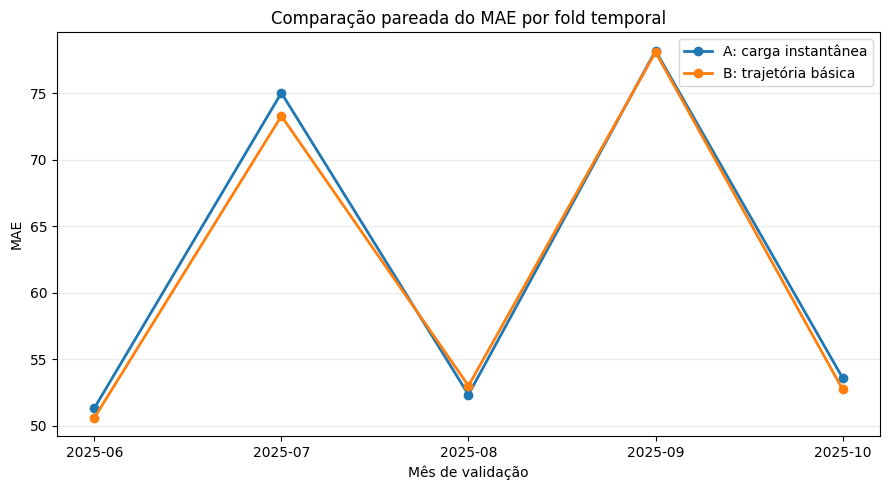

Figura salva em: /content/drive/MyDrive/co2-cems-thermal-modeling/outputs/figures/03A03_mae_folds_AB.png


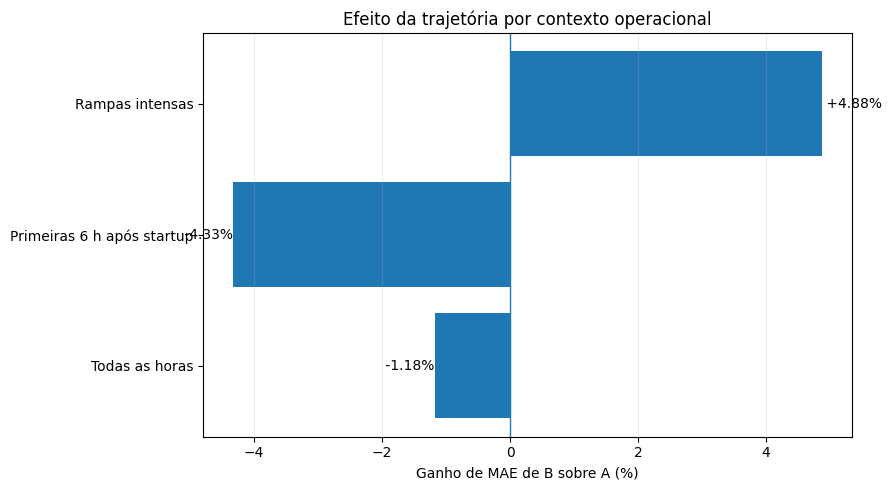

Figura salva em: /content/drive/MyDrive/co2-cems-thermal-modeling/outputs/figures/03A03_contextos_operacionais_AB.png


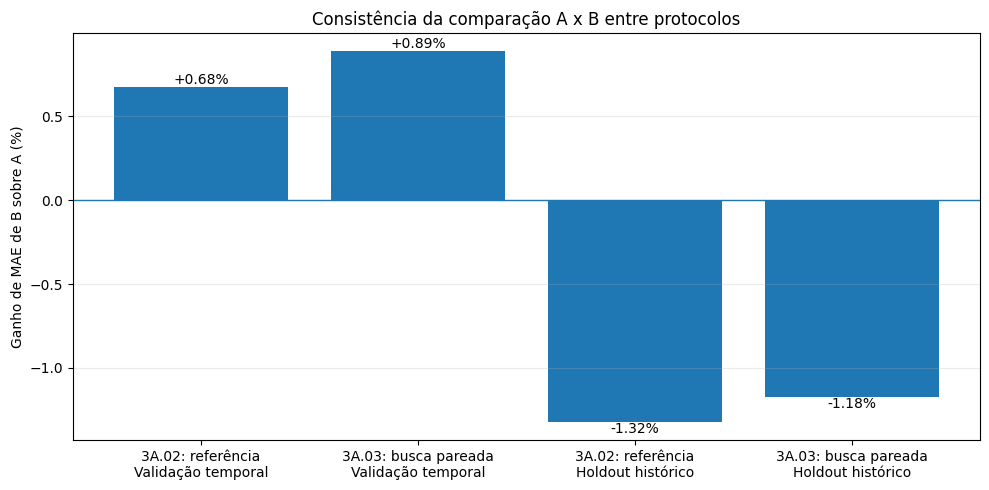

Figura salva em: /content/drive/MyDrive/co2-cems-thermal-modeling/outputs/figures/03A03_consistencia_protocolos_AB.png


In [52]:
# ============================================================
# CÉLULA 16: FIGURAS FINAIS
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Produzir representações visuais da comparação A x B.
#
# Serão geradas:
#
#   1. MAE por fold temporal;
#   2. ganho de B por contexto operacional;
#   3. ganho de B nos dois protocolos experimentais.
# ============================================================


# ============================================================
# FIGURA 1: MAE POR FOLD
# ============================================================

fig, ax = plt.subplots(
    figsize=(
        9,
        5
    )
)


x = np.arange(
    len(
        paired_folds
    )
)


ax.plot(

    x,

    paired_folds[
        "MAE_A"
    ],

    marker="o",

    linewidth=2,

    label=
        "A: carga instantânea"

)


ax.plot(

    x,

    paired_folds[
        "MAE_B"
    ],

    marker="o",

    linewidth=2,

    label=
        "B: trajetória básica"

)


ax.set_xticks(
    x
)


ax.set_xticklabels(

    paired_folds[
        "validation_month"
    ]

)


ax.set_xlabel(
    "Mês de validação"
)


ax.set_ylabel(
    "MAE"
)


ax.set_title(
    "Comparação pareada do MAE por fold temporal"
)


ax.legend()


ax.grid(
    axis="y",
    alpha=0.25
)


fig.tight_layout()


FOLD_FIGURE_PATH = (

    FIGURES
    /
    "03A03_mae_folds_AB.png"

)


fig.savefig(

    FOLD_FIGURE_PATH,

    dpi=300,

    bbox_inches="tight"

)


plt.show()


print(
    "Figura salva em:",
    FOLD_FIGURE_PATH
)


# ============================================================
# FIGURA 2: CONTEXTOS OPERACIONAIS
# ============================================================

context_plot = (

    optimized_context_results

    .copy()

)


fig, ax = plt.subplots(
    figsize=(
        9,
        5
    )
)


bars = ax.barh(

    context_plot[
        "contexto"
    ],

    context_plot[
        "ganho_B_vs_A_%"
    ]

)


ax.axvline(

    0,

    linewidth=1

)


ax.set_xlabel(
    "Ganho de MAE de B sobre A (%)"
)


ax.set_ylabel(
    ""
)


ax.set_title(
    "Efeito da trajetória por contexto operacional"
)


ax.grid(
    axis="x",
    alpha=0.25
)


for bar, value in zip(

    bars,

    context_plot[
        "ganho_B_vs_A_%"
    ]

):

    ax.text(

        value,

        bar.get_y()
        +
        bar.get_height() / 2,

        f" {value:+.2f}%",

        va="center",

        ha=
            "left"
            if value >= 0
            else
            "right"

    )


fig.tight_layout()


CONTEXT_FIGURE_PATH = (

    FIGURES
    /
    "03A03_contextos_operacionais_AB.png"

)


fig.savefig(

    CONTEXT_FIGURE_PATH,

    dpi=300,

    bbox_inches="tight"

)


plt.show()


print(
    "Figura salva em:",
    CONTEXT_FIGURE_PATH
)


# ============================================================
# FIGURA 3: CONSISTÊNCIA ENTRE PROTOCOLOS
# ============================================================

protocol_plot = (

    protocol_comparison

    .copy()

)


protocol_plot[
    "rotulo"
] = (

    protocol_plot[
        "protocolo"
    ]

    +

    "\n"

    +

    protocol_plot[
        "avaliacao"
    ]

)


fig, ax = plt.subplots(
    figsize=(
        10,
        5
    )
)


bars = ax.bar(

    protocol_plot[
        "rotulo"
    ],

    protocol_plot[
        "ganho_B_vs_A_%"
    ]

)


ax.axhline(

    0,

    linewidth=1

)


ax.set_ylabel(
    "Ganho de MAE de B sobre A (%)"
)


ax.set_xlabel(
    ""
)


ax.set_title(
    "Consistência da comparação A x B entre protocolos"
)


ax.grid(
    axis="y",
    alpha=0.25
)


for bar, value in zip(

    bars,

    protocol_plot[
        "ganho_B_vs_A_%"
    ]

):

    ax.text(

        bar.get_x()
        +
        bar.get_width() / 2,

        value,

        f"{value:+.2f}%",

        ha="center",

        va=
            "bottom"
            if value >= 0
            else
            "top"

    )


fig.tight_layout()


PROTOCOL_FIGURE_PATH = (

    FIGURES
    /
    "03A03_consistencia_protocolos_AB.png"

)


fig.savefig(

    PROTOCOL_FIGURE_PATH,

    dpi=300,

    bbox_inches="tight"

)


plt.show()


print(
    "Figura salva em:",
    PROTOCOL_FIGURE_PATH
)

In [53]:
# ============================================================
# CÉLULA 17: SALVAR RESULTADOS DO NOTEBOOK
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Persistir todas as informações relevantes produzidas pelo
# experimento.
#
# Isso evita a necessidade de executar novamente os 300
# treinamentos para análises posteriores.
# ============================================================


# ============================================================
# 1. CAMINHOS DAS TABELAS
# ============================================================

TUNING_RESULTS_PATH = (

    TABLES
    /
    "03A03_tuning_results_AB.csv"

)


TUNING_SUMMARY_PATH = (

    TABLES
    /
    "03A03_tuning_summary_AB.csv"

)


PAIRED_FOLDS_PATH = (

    TABLES
    /
    "03A03_paired_folds_AB.csv"

)


OPTIMIZATION_COMPARISON_PATH = (

    TABLES
    /
    "03A03_comparacao_busca_baseline.csv"

)


HOLDOUT_PATH = (

    TABLES
    /
    "03A03_holdout_AB.csv"

)


CONTEXT_PATH = (

    TABLES
    /
    "03A03_contextos_operacionais_AB.csv"

)


PROTOCOL_COMPARISON_PATH = (

    TABLES
    /
    "03A03_consistencia_protocolos_AB.csv"

)


PREDICTIONS_PATH = (

    TABLES
    /
    "03A03_previsoes_holdout_AB.csv"

)


BEST_CONFIGS_PATH = (

    TABLES
    /
    "03A03_best_configs_AB.json"

)


# ============================================================
# 2. PREVISÕES DO HOLDOUT
# ============================================================

holdout_predictions = pd.DataFrame({

    "timestamp":

        holdout_data[
            "timestamp"
        ]
        .to_numpy(),

    "observado":

        y_holdout,

    "pred_A":

        pred_A_opt,

    "pred_B":

        pred_B_opt

})


holdout_predictions[
    "erro_abs_A"
] = np.abs(

    holdout_predictions[
        "observado"
    ]

    -

    holdout_predictions[
        "pred_A"
    ]

)


holdout_predictions[
    "erro_abs_B"
] = np.abs(

    holdout_predictions[
        "observado"
    ]

    -

    holdout_predictions[
        "pred_B"
    ]

)


# ============================================================
# 3. SALVAR TABELAS
# ============================================================

tuning_results.to_csv(

    TUNING_RESULTS_PATH,

    index=False

)


tuning_summary.to_csv(

    TUNING_SUMMARY_PATH,

    index=False

)


paired_folds.to_csv(

    PAIRED_FOLDS_PATH,

    index=False

)


optimization_comparison.to_csv(

    OPTIMIZATION_COMPARISON_PATH,

    index=False

)


optimized_holdout.to_csv(

    HOLDOUT_PATH,

    index=False

)


optimized_context_results.to_csv(

    CONTEXT_PATH,

    index=False

)


protocol_comparison.to_csv(

    PROTOCOL_COMPARISON_PATH,

    index=False

)


holdout_predictions.to_csv(

    PREDICTIONS_PATH,

    index=False

)


# ============================================================
# 4. CONVERTER TIPOS NUMPY PARA TIPOS NATIVOS
# ============================================================

def to_python_scalar(
    value
):

    if isinstance(
        value,
        np.integer
    ):

        return int(
            value
        )

    if isinstance(
        value,
        np.floating
    ):

        return float(
            value
        )

    return value


# ============================================================
# 5. SALVAR MELHORES HIPERPARÂMETROS
# ============================================================

best_configs_output = {

    "A": {

        key:
            to_python_scalar(
                value
            )

        for (
            key,
            value
        ) in best_config_A.items()

    },

    "B": {

        key:
            to_python_scalar(
                value
            )

        for (
            key,
            value
        ) in best_config_B.items()

    }

}


with open(

    BEST_CONFIGS_PATH,

    "w",

    encoding="utf-8"

) as f:

    json.dump(

        best_configs_output,

        f,

        indent=4,

        ensure_ascii=False

    )


# ============================================================
# 6. CONFIRMAÇÃO
# ============================================================

saved_files = [

    TUNING_RESULTS_PATH,

    TUNING_SUMMARY_PATH,

    PAIRED_FOLDS_PATH,

    OPTIMIZATION_COMPARISON_PATH,

    HOLDOUT_PATH,

    CONTEXT_PATH,

    PROTOCOL_COMPARISON_PATH,

    PREDICTIONS_PATH,

    BEST_CONFIGS_PATH

]


print("=" * 72)

print(
    "ARQUIVOS SALVOS"
)

print("=" * 72)


for file_path in saved_files:

    print(
        file_path
    )

ARQUIVOS SALVOS
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A03_tuning_results_AB.csv
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A03_tuning_summary_AB.csv
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A03_paired_folds_AB.csv
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A03_comparacao_busca_baseline.csv
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A03_holdout_AB.csv
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A03_contextos_operacionais_AB.csv
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A03_consistencia_protocolos_AB.csv
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A03_previsoes_holdout_AB.csv
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A03_best_configs_AB.json


In [54]:
# ============================================================
# CÉLULA 18: RELATÓRIO FINAL DO NOTEBOOK 3A.03
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Registrar:
#
#   1. metodologia da busca pareada;
#   2. hiperparâmetros selecionados;
#   3. desempenho na validação temporal;
#   4. desempenho no holdout histórico;
#   5. diagnóstico por contexto operacional;
#   6. comparação com o Notebook 3A.02;
#   7. conclusão sobre o valor incremental da trajetória;
#   8. limitações da evidência disponível;
#   9. questão subsequente decorrente dos resultados.
#
# IMPORTANTE
# ------------------------------------------------------------
# O Notebook 3A.03 NÃO define o modelo final da Iatan.
#
# Ele responde apenas se, dentro do experimento realizado,
# a trajetória operacional básica apresenta ganho preditivo
# consistente em relação à carga instantânea.
#
# O protocolo aqui executado não fornece uma validação final
# independente da generalização temporal.
# ============================================================


REPORT_PATH = (

    REPORTS
    /
    "relatorio_modelagem_preditiva_03A03.md"

)


# ============================================================
# 1. TABELAS PARA O RELATÓRIO
# ============================================================

best_configs_report = pd.DataFrame([

    {

        "Cenário":
            "A",

        "Features":
            len(
                FEATURES_A
            ),

        "Configuração":
            best_config_A_id,

        **best_config_A

    },

    {

        "Cenário":
            "B",

        "Features":
            len(
                FEATURES_B
            ),

        "Configuração":
            best_config_B_id,

        **best_config_B

    }

])


cv_report = (

    paired_folds

    .copy()

    .round(3)

)


holdout_report = (

    optimized_holdout

    .copy()

    .round(4)

)


context_report = (

    optimized_context_results

    .copy()

    .round(3)

)


protocol_report = (

    protocol_comparison

    .copy()

    .round(3)

)


# ============================================================
# 2. CONSTRUIR RELATÓRIO
# ============================================================

report = f"""
# Relatório: Notebook 3A.03

## 1. Objetivo

Realizar uma busca pareada de hiperparâmetros para os Cenários A
e B utilizando a mesma família de modelo, o mesmo espaço de busca,
as mesmas configurações candidatas e os mesmos cinco folds
temporais.

A pergunta investigada foi:

> Após busca controlada de hiperparâmetros da mesma família de
> modelo, a inclusão de informações de trajetória operacional
> oferece ganho preditivo consistente em relação ao uso exclusivo
> da carga instantânea?

---

## 2. Cenários avaliados

### Cenário A

Carga instantânea:

`CO₂(t) = f(P(t))`

Número de features: **{len(FEATURES_A)}**

### Cenário B

Carga instantânea e trajetória operacional básica.

Número de features: **{len(FEATURES_B)}**

---

## 3. Estratégia de busca

Foram sorteadas **{N_CONFIGS} configurações** de hiperparâmetros
com `ParameterSampler` e semente aleatória igual a **{SEED}**.

Cada configuração foi avaliada:

- no Cenário A;
- no Cenário B;
- nos mesmos cinco folds temporais.

Número total de ajustes:

**{len(tuning_results)} modelos**

A métrica primária de seleção foi o **MAE médio dos cinco folds**.

O holdout histórico de novembro e dezembro não participou da
seleção dos hiperparâmetros.

### Fundamentação metodológica da otimização

**Random Search (busca aleatória de hiperparâmetros).**
O `ParameterSampler` sorteia combinações do espaço de busca
previamente definido. O uso de `random_state=SEED` permite
reproduzir a seleção das configurações candidatas. Ao contrário
de uma busca exaustiva (*Grid Search*), não é necessário testar
todas as combinações possíveis. Neste experimento, o número
de árvores (`n_estimators`) é otimizado explicitamente; não se
utiliza *early stopping* durante a busca.

**Walk-forward temporal cross-validation with an expanding
training window (validação cruzada temporal com janela expansiva).**
Os cinco folds avançam cronologicamente: o treinamento começa
em janeiro e incorpora progressivamente novos meses, enquanto
cada validação utiliza o mês imediatamente posterior ao fim da
respectiva janela de treino. Essa estrutura evita embaralhar
observações futuras com dados passados e distingue o procedimento
de uma validação cruzada aleatória do tipo `KFold`.

**Paired experimental design (desenho experimental pareado).**
Os dois cenários utilizam as mesmas observações elegíveis, o
mesmo conjunto de configurações candidatas, os mesmos folds
e a mesma métrica de avaliação. Assim, as diferenças entre A
e B são examinadas sob condições experimentais comparáveis,
com a representação das variáveis como principal contraste.
Entretanto, a melhor configuração é selecionada separadamente
para cada cenário, a partir do MAE médio de validação. Portanto,
o pareamento não significa que os modelos finais precisem ter
hiperparâmetros idênticos, nem constitui um teste formal de
significância estatística.

**Final refit (reajuste final).** Após a seleção dos
hiperparâmetros, os modelos são novamente treinados com todo
o período de desenvolvimento, de janeiro a outubro. Os meses
de novembro e dezembro são utilizados apenas na avaliação
histórica posterior, com a ressalva de já terem sido observados
em etapas anteriores da pesquisa.

---

## 4. Configurações selecionadas

{best_configs_report.to_markdown(index=False)}

---

## 5. Validação temporal pareada

{cv_report.to_markdown(index=False)}

O Cenário B apresentou menor MAE em **{b_wins} de {len(paired_folds)} folds**.

O ganho médio de MAE de A para B foi de:

**{cv_gain_B_vs_A:+.2f}%**

Apesar de B vencer quatro dos cinco folds, a magnitude média do
ganho foi inferior a 1%.

---

## 6. Comparação com as configurações de referência

A busca do Notebook 3A.03 utiliza um protocolo de treinamento
diferente daquele utilizado no Notebook 3A.02.

No Notebook 3A.02:

- `n_estimators` máximo igual a 3000;
- `early_stopping_rounds` igual a 50.

No Notebook 3A.03:

- `n_estimators` foi tratado explicitamente como hiperparâmetro;
- não foi utilizado early stopping.

Por esse motivo, a diferença absoluta de MAE entre os dois
notebooks não deve ser interpretada isoladamente como efeito
da busca de hiperparâmetros.

O objetivo principal desta comparação é verificar a consistência
da relação relativa entre A e B.

{protocol_report.to_markdown(index=False)}

Nos dois protocolos foi observado o mesmo padrão:

- B apresenta pequena vantagem média na validação temporal;
- essa vantagem não se reproduz no holdout histórico.

Essa repetição do comportamento em dois protocolos distintos
reforça a interpretação de que o benefício global das variáveis
adicionais de trajetória é limitado.

---

## 7. Holdout histórico

{holdout_report.to_markdown(index=False)}

O ganho de MAE de B em relação a A no holdout histórico foi:

**{holdout_gain_B_vs_A:+.2f}%**

Portanto, o Cenário B não superou o Cenário A no desempenho
global de novembro e dezembro.

É importante ressaltar que esse período já foi utilizado ao longo
do desenvolvimento dos experimentos anteriores.

Por esse motivo, novembro e dezembro devem ser tratados como
**holdout histórico de comparação**, e não como teste final
completamente cego.

---

## 8. Contextos operacionais

O limiar utilizado para identificar rampas intensas foi:

**{RAMP_THRESHOLD:.2f} MW/h**

Esse valor corresponde ao percentil 90 de `abs_delta_load_1h`
calculado exclusivamente no período de desenvolvimento.

{context_report.to_markdown(index=False)}

Nas primeiras seis horas após startup, B apresentou desempenho
inferior a A.

Em rampas intensas, entretanto, B apresentou redução de MAE de:

**{ramp_result['ganho_B_vs_A_%']:+.2f}%**

Esse resultado sugere que as informações de trajetória podem
possuir valor preditivo localizado durante mudanças operacionais
mais intensas.

Entretanto, o subconjunto de rampas contém apenas
**{int(ramp_result['n'])} observações**.

Portanto, esse resultado deve ser interpretado como evidência
exploratória e não como demonstração definitiva de superioridade
do Cenário B em regimes transitórios.

---

## 9. Interpretação

A busca pareada não fornece evidência de que a trajetória
operacional produza ganho preditivo global suficientemente
consistente para justificar, neste momento, a maior complexidade
do Cenário B.

A validação temporal favoreceu B em quatro dos cinco folds, mas
o ganho médio foi pequeno:

**{cv_gain_B_vs_A:+.2f}%**

Além disso, o resultado não se reproduziu no holdout histórico:

**{holdout_gain_B_vs_A:+.2f}%**

A comparação com o Notebook 3A.02 reforça essa interpretação,
pois o mesmo padrão qualitativo foi observado utilizando outro
protocolo de treinamento.

Isso não significa que os processos ou estágios operacionais
sejam irrelevantes para as emissões de CO₂.

A conclusão é mais específica:

> Para a Iatan Unit 2, considerando os dados de 2025 e as
> variáveis de trajetória avaliadas, essas informações não
> apresentaram ganho preditivo global consistente além daquele
> obtido com a carga instantânea.

A melhora observada durante rampas intensas sugere que o valor
da trajetória pode depender do regime operacional.

---

## 10. Parcimônia

O Cenário A utiliza apenas **1 feature**.

O Cenário B utiliza **7 features**.

Como o aumento de complexidade não produziu benefício global
consistente, o princípio de parcimônia favorece o Cenário A
como representação de referência para os experimentos seguintes
na Iatan.

Essa escolha não significa que A seja considerado, neste estágio,
o modelo final da unidade.

Ela significa apenas que a carga instantânea constitui o ponto
de partida mais simples e competitivo para os próximos testes.

---

## 11. Conclusão do Notebook 3A.03

A resposta à pergunta específica deste notebook é:

> **Não foi observada evidência robusta de que a inclusão das
> informações de trajetória operacional melhore de forma global
> e consistente o XGBoost em relação ao uso exclusivo da carga
> instantânea.**

O Cenário B apresentou pequeno ganho médio na validação temporal,
mas esse ganho não se reproduziu no holdout histórico.

O ganho observado durante rampas intensas indica, entretanto,
que a trajetória operacional pode possuir valor localizado em
regimes dinâmicos específicos.

A persistência desse possível benefício em outros períodos
permanece indeterminada neste notebook.

---

## 12. Limitação da evidência disponível

Os resultados obtidos até o Notebook 3A.03 não são suficientes
para afirmar que foi encontrado o melhor modelo possível para a
Iatan Unit 2.

Até este ponto, a maior parte dos experimentos utiliza apenas o
ano de **2025**.

Consequentemente, ainda não foi respondida uma questão central:

> **O desempenho preditivo melhora quando o volume de dados
> históricos utilizado no treinamento aumenta?**

Também permanece em aberto outra questão fundamental:

> **Um modelo desenvolvido com dados históricos consegue manter
> desempenho satisfatório em um período futuro completamente
> ausente das etapas de treinamento, seleção de features e
> escolha de hiperparâmetros?**

A diferença observada entre os erros da validação temporal e do
holdout histórico também indica que a dificuldade da previsão
varia ao longo do tempo.

Portanto, um bom resultado em novembro e dezembro de 2025 não
deve ser interpretado isoladamente como demonstração definitiva
da precisão do modelo.

---

## 13. Limitações e direcionamento da investigação subsequente

Este notebook avaliou o ganho incremental das variáveis de trajetória
operacional para a Iatan Unit 2, a partir dos dados de 2025, com
otimização pareada do XGBoost. Os resultados não demonstraram
superioridade global consistente do Cenário B sobre o Cenário A.
A melhora observada nas rampas intensas permanece uma evidência
exploratória restrita ao subconjunto avaliado.

O desempenho nos cinco folds variou entre meses, e novembro e
dezembro de 2025 já haviam sido utilizados em experimentos
anteriores. Portanto, esta análise **não constitui uma avaliação
final e independente da generalização temporal**, tampouco define
um modelo definitivo para a unidade.

Uma questão permaneceu sem resposta ao término do experimento:
**qual é o efeito da quantidade de histórico de treinamento sobre
o erro de previsão e sua estabilidade entre períodos?** Essa
limitação motivou o Notebook 3A.04, voltado à avaliação do volume
de dados históricos e da generalização temporal na própria Iatan
Unit 2.

A identificação dessa questão não implica assumir outras etapas
experimentais. Investigações adicionais dependem dos resultados
obtidos, de sua pertinência para a pergunta de pesquisa e das
condições efetivas de análise.
"""


# ============================================================
# 3. SALVAR RELATÓRIO
# ============================================================

with open(

    REPORT_PATH,

    "w",

    encoding="utf-8"

) as f:

    f.write(
        report
    )


# ============================================================
# 4. MOSTRAR RELATÓRIO
# ============================================================

print(
    "Relatório salvo em:"
)

print(
    REPORT_PATH
)


display(
    Markdown(
        report
    )
)

Relatório salvo em:
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/reports/relatorio_modelagem_preditiva_03A03.md



# Relatório: Notebook 3A.03

## 1. Objetivo

Realizar uma busca pareada de hiperparâmetros para os Cenários A
e B utilizando a mesma família de modelo, o mesmo espaço de busca,
as mesmas configurações candidatas e os mesmos cinco folds
temporais.

A pergunta investigada foi:

> Após busca controlada de hiperparâmetros da mesma família de
> modelo, a inclusão de informações de trajetória operacional
> oferece ganho preditivo consistente em relação ao uso exclusivo
> da carga instantânea?

---

## 2. Cenários avaliados

### Cenário A

Carga instantânea:

`CO₂(t) = f(P(t))`

Número de features: **1**

### Cenário B

Carga instantânea e trajetória operacional básica.

Número de features: **7**

---

## 3. Estratégia de busca

Foram sorteadas **30 configurações** de hiperparâmetros
com `ParameterSampler` e semente aleatória igual a **42**.

Cada configuração foi avaliada:

- no Cenário A;
- no Cenário B;
- nos mesmos cinco folds temporais.

Número total de ajustes:

**300 modelos**

A métrica primária de seleção foi o **MAE médio dos cinco folds**.

O holdout histórico de novembro e dezembro não participou da
seleção dos hiperparâmetros.

### Fundamentação metodológica da otimização

**Random Search (busca aleatória de hiperparâmetros).**
O `ParameterSampler` sorteia combinações do espaço de busca
previamente definido. O uso de `random_state=SEED` permite
reproduzir a seleção das configurações candidatas. Ao contrário
de uma busca exaustiva (*Grid Search*), não é necessário testar
todas as combinações possíveis. Neste experimento, o número
de árvores (`n_estimators`) é otimizado explicitamente; não se
utiliza *early stopping* durante a busca.

**Walk-forward temporal cross-validation with an expanding
training window (validação cruzada temporal com janela expansiva).**
Os cinco folds avançam cronologicamente: o treinamento começa
em janeiro e incorpora progressivamente novos meses, enquanto
cada validação utiliza o mês imediatamente posterior ao fim da
respectiva janela de treino. Essa estrutura evita embaralhar
observações futuras com dados passados e distingue o procedimento
de uma validação cruzada aleatória do tipo `KFold`.

**Paired experimental design (desenho experimental pareado).**
Os dois cenários utilizam as mesmas observações elegíveis, o
mesmo conjunto de configurações candidatas, os mesmos folds
e a mesma métrica de avaliação. Assim, as diferenças entre A
e B são examinadas sob condições experimentais comparáveis,
com a representação das variáveis como principal contraste.
Entretanto, a melhor configuração é selecionada separadamente
para cada cenário, a partir do MAE médio de validação. Portanto,
o pareamento não significa que os modelos finais precisem ter
hiperparâmetros idênticos, nem constitui um teste formal de
significância estatística.

**Final refit (reajuste final).** Após a seleção dos
hiperparâmetros, os modelos são novamente treinados com todo
o período de desenvolvimento, de janeiro a outubro. Os meses
de novembro e dezembro são utilizados apenas na avaliação
histórica posterior, com a ressalva de já terem sido observados
em etapas anteriores da pesquisa.

---

## 4. Configurações selecionadas

| Cenário   |   Features | Configuração   |   subsample |   reg_lambda |   reg_alpha |   n_estimators |   min_child_weight |   max_depth |   learning_rate |   gamma |   colsample_bytree |
|:----------|-----------:|:---------------|------------:|-------------:|------------:|---------------:|-------------------:|------------:|----------------:|--------:|-------------------:|
| A         |          1 | CFG_10         |        0.85 |            5 |         0.5 |            200 |                  5 |           6 |            0.01 |    0.25 |                  1 |
| B         |          7 | CFG_28         |        1    |           10 |         0.5 |            200 |                  3 |           6 |            0.01 |    0.5  |                  1 |

---

## 5. Validação temporal pareada

|   fold | validation_month   |   MAE_A |   RMSE_A |   R2_A |   MAE_B |   RMSE_B |   R2_B |   ganho_MAE_B_vs_A_% |
|-------:|:-------------------|--------:|---------:|-------:|--------:|---------:|-------:|---------------------:|
|      1 | 2025-06            |  51.332 |   86.273 |  0.855 |  50.605 |   85.393 |  0.858 |                1.415 |
|      2 | 2025-07            |  75.011 |   88.364 |  0.814 |  73.275 |   86.502 |  0.822 |                2.314 |
|      3 | 2025-08            |  52.349 |   58.449 |  0.854 |  53.011 |   59.109 |  0.85  |               -1.263 |
|      4 | 2025-09            |  78.181 |   82.875 |  0.78  |  78.082 |   81.886 |  0.785 |                0.126 |
|      5 | 2025-10            |  53.609 |   62.941 |  0.931 |  52.75  |   63.869 |  0.929 |                1.602 |

O Cenário B apresentou menor MAE em **4 de 5 folds**.

O ganho médio de MAE de A para B foi de:

**+0.89%**

Apesar de B vencer quatro dos cinco folds, a magnitude média do
ganho foi inferior a 1%.

---

## 6. Comparação com as configurações de referência

A busca do Notebook 3A.03 utiliza um protocolo de treinamento
diferente daquele utilizado no Notebook 3A.02.

No Notebook 3A.02:

- `n_estimators` máximo igual a 3000;
- `early_stopping_rounds` igual a 50.

No Notebook 3A.03:

- `n_estimators` foi tratado explicitamente como hiperparâmetro;
- não foi utilizado early stopping.

Por esse motivo, a diferença absoluta de MAE entre os dois
notebooks não deve ser interpretada isoladamente como efeito
da busca de hiperparâmetros.

O objetivo principal desta comparação é verificar a consistência
da relação relativa entre A e B.

| protocolo            | avaliacao          |   MAE_A |   MAE_B |   ganho_B_vs_A_% |
|:---------------------|:-------------------|--------:|--------:|-----------------:|
| 3A.02: referência    | Validação temporal |  56.613 |  56.23  |            0.677 |
| 3A.03: busca pareada | Validação temporal |  62.096 |  61.545 |            0.888 |
| 3A.02: referência    | Holdout histórico  |  22.962 |  23.266 |           -1.32  |
| 3A.03: busca pareada | Holdout histórico  |  38.898 |  39.356 |           -1.176 |

Nos dois protocolos foi observado o mesmo padrão:

- B apresenta pequena vantagem média na validação temporal;
- essa vantagem não se reproduz no holdout histórico.

Essa repetição do comportamento em dois protocolos distintos
reforça a interpretação de que o benefício global das variáveis
adicionais de trajetória é limitado.

---

## 7. Holdout histórico

| cenario                   |   n_features |     MAE |    RMSE |     R2 |
|:--------------------------|-------------:|--------:|--------:|-------:|
| A-XGBoost (busca pareada) |            1 | 38.8984 | 45.0646 | 0.9507 |
| B-XGBoost (busca pareada) |            7 | 39.3558 | 46.2507 | 0.948  |

O ganho de MAE de B em relação a A no holdout histórico foi:

**-1.18%**

Portanto, o Cenário B não superou o Cenário A no desempenho
global de novembro e dezembro.

É importante ressaltar que esse período já foi utilizado ao longo
do desenvolvimento dos experimentos anteriores.

Por esse motivo, novembro e dezembro devem ser tratados como
**holdout histórico de comparação**, e não como teste final
completamente cego.

---

## 8. Contextos operacionais

O limiar utilizado para identificar rampas intensas foi:

**130.00 MW/h**

Esse valor corresponde ao percentil 90 de `abs_delta_load_1h`
calculado exclusivamente no período de desenvolvimento.

| contexto                   |    n |   MAE_A |   MAE_B |   ganho_B_vs_A_% |
|:---------------------------|-----:|--------:|--------:|-----------------:|
| Todas as horas             | 1144 |  38.898 |  39.356 |           -1.176 |
| Primeiras 6 h após startup |   30 |  83.66  |  87.287 |           -4.335 |
| Rampas intensas            |  115 |  30.381 |  28.898 |            4.879 |

Nas primeiras seis horas após startup, B apresentou desempenho
inferior a A.

Em rampas intensas, entretanto, B apresentou redução de MAE de:

**+4.88%**

Esse resultado sugere que as informações de trajetória podem
possuir valor preditivo localizado durante mudanças operacionais
mais intensas.

Entretanto, o subconjunto de rampas contém apenas
**115 observações**.

Portanto, esse resultado deve ser interpretado como evidência
exploratória e não como demonstração definitiva de superioridade
do Cenário B em regimes transitórios.

---

## 9. Interpretação

A busca pareada não fornece evidência de que a trajetória
operacional produza ganho preditivo global suficientemente
consistente para justificar, neste momento, a maior complexidade
do Cenário B.

A validação temporal favoreceu B em quatro dos cinco folds, mas
o ganho médio foi pequeno:

**+0.89%**

Além disso, o resultado não se reproduziu no holdout histórico:

**-1.18%**

A comparação com o Notebook 3A.02 reforça essa interpretação,
pois o mesmo padrão qualitativo foi observado utilizando outro
protocolo de treinamento.

Isso não significa que os processos ou estágios operacionais
sejam irrelevantes para as emissões de CO₂.

A conclusão é mais específica:

> Para a Iatan Unit 2, considerando os dados de 2025 e as
> variáveis de trajetória avaliadas, essas informações não
> apresentaram ganho preditivo global consistente além daquele
> obtido com a carga instantânea.

A melhora observada durante rampas intensas sugere que o valor
da trajetória pode depender do regime operacional.

---

## 10. Parcimônia

O Cenário A utiliza apenas **1 feature**.

O Cenário B utiliza **7 features**.

Como o aumento de complexidade não produziu benefício global
consistente, o princípio de parcimônia favorece o Cenário A
como representação de referência para os experimentos seguintes
na Iatan.

Essa escolha não significa que A seja considerado, neste estágio,
o modelo final da unidade.

Ela significa apenas que a carga instantânea constitui o ponto
de partida mais simples e competitivo para os próximos testes.

---

## 11. Conclusão do Notebook 3A.03

A resposta à pergunta específica deste notebook é:

> **Não foi observada evidência robusta de que a inclusão das
> informações de trajetória operacional melhore de forma global
> e consistente o XGBoost em relação ao uso exclusivo da carga
> instantânea.**

O Cenário B apresentou pequeno ganho médio na validação temporal,
mas esse ganho não se reproduziu no holdout histórico.

O ganho observado durante rampas intensas indica, entretanto,
que a trajetória operacional pode possuir valor localizado em
regimes dinâmicos específicos.

A persistência desse possível benefício em outros períodos
permanece indeterminada neste notebook.

---

## 12. Limitação da evidência disponível

Os resultados obtidos até o Notebook 3A.03 não são suficientes
para afirmar que foi encontrado o melhor modelo possível para a
Iatan Unit 2.

Até este ponto, a maior parte dos experimentos utiliza apenas o
ano de **2025**.

Consequentemente, ainda não foi respondida uma questão central:

> **O desempenho preditivo melhora quando o volume de dados
> históricos utilizado no treinamento aumenta?**

Também permanece em aberto outra questão fundamental:

> **Um modelo desenvolvido com dados históricos consegue manter
> desempenho satisfatório em um período futuro completamente
> ausente das etapas de treinamento, seleção de features e
> escolha de hiperparâmetros?**

A diferença observada entre os erros da validação temporal e do
holdout histórico também indica que a dificuldade da previsão
varia ao longo do tempo.

Portanto, um bom resultado em novembro e dezembro de 2025 não
deve ser interpretado isoladamente como demonstração definitiva
da precisão do modelo.

---

## 13. Limitações e direcionamento da investigação subsequente

Este notebook avaliou o ganho incremental das variáveis de trajetória
operacional para a Iatan Unit 2, a partir dos dados de 2025, com
otimização pareada do XGBoost. Os resultados não demonstraram
superioridade global consistente do Cenário B sobre o Cenário A.
A melhora observada nas rampas intensas permanece uma evidência
exploratória restrita ao subconjunto avaliado.

O desempenho nos cinco folds variou entre meses, e novembro e
dezembro de 2025 já haviam sido utilizados em experimentos
anteriores. Portanto, esta análise **não constitui uma avaliação
final e independente da generalização temporal**, tampouco define
um modelo definitivo para a unidade.

Uma questão permaneceu sem resposta ao término do experimento:
**qual é o efeito da quantidade de histórico de treinamento sobre
o erro de previsão e sua estabilidade entre períodos?** Essa
limitação motivou o Notebook 3A.04, voltado à avaliação do volume
de dados históricos e da generalização temporal na própria Iatan
Unit 2.

A identificação dessa questão não implica assumir outras etapas
experimentais. Investigações adicionais dependem dos resultados
obtidos, de sua pertinência para a pergunta de pesquisa e das
condições efetivas de análise.


## Referências

BERGSTRA, J.; BENGIO, Y. Random Search for Hyper-Parameter Optimization. **Journal of Machine Learning Research**, *[s. l.]*, v. 13, n. 10, p. 281-305, 2012. Disponível em: https://jmlr.org/papers/v13/bergstra12a.html. Acesso em: 24 out. 2026.

CAWLEY, G. C.; TALBOT, N. L. C. On Over-fitting in Model Selection and Subsequent Selection Bias in Performance Evaluation. **Journal of Machine Learning Research**, *[s. l.]*, v. 11, n. 70, p. 2079-2107, 2010. Disponível em: https://jmlr.org/papers/v11/cawley10a.html. Acesso em: 24 out. 2026.

CERQUEIRA, V.; TORGO, L.; MOZETIČ, I. Evaluating time series forecasting models: an empirical study on performance estimation methods. **Machine Learning**, *[s. l.]*, v. 109, n. 11, p. 1997-2028, 2020. DOI: https://doi.org/10.1007/s10994-020-05910-7. Disponível em: https://link.springer.com/article/10.1007/s10994-020-05910-7. Acesso em: 24 out. 2026.

CHEN, T.; GUESTRIN, C. XGBoost: A Scalable Tree Boosting System. *In:* ACM SIGKDD INTERNATIONAL CONFERENCE ON KNOWLEDGE DISCOVERY AND DATA MINING, 22., 2016, San Francisco. **Proceedings [...]**. New York: ACM, 2016. p. 785-794. DOI: https://doi.org/10.1145/2939672.2939785. Disponível em: https://www.kdd.org/kdd2016/papers/files/rfp0697-chenAemb.pdf. Acesso em: 24 out. 2026.

FRIEDMAN, J. H. Greedy function approximation: A gradient boosting machine. **The Annals of Statistics**, *[s. l.]*, v. 29, n. 5, p. 1189-1232, 2001. DOI: https://doi.org/10.1214/aos/1013203451. Disponível em: https://projecteuclid.org/journals/annals-of-statistics/volume-29/issue-5/Greedy-function-approximation-A-gradient-boosting-machine/10.1214/aos/1013203451.full. Acesso em: 24 out. 2026.

HYNDMAN, R. J.; KOEHLER, A. B. Another look at measures of forecast accuracy. **International Journal of Forecasting**, *[s. l.]*, v. 22, n. 4, p. 679-688, 2006. DOI: https://doi.org/10.1016/j.ijforecast.2006.03.001. Disponível em: https://robjhyndman.com/publications/another-look-at-measures-of-forecast-accuracy/. Acesso em: 24 out. 2026.

SCIKIT-LEARN. **User Guide**. Version 1.8.0. *[S. l.]*: The scikit-learn developers, [2025]. Seções MinMaxScaler e Regression metrics. Disponível em: https://scikit-learn.org/1.8/modules/generated/sklearn.preprocessing.MinMaxScaler.html e https://scikit-learn.org/1.8/modules/model_evaluation.html#regression-metrics. Acesso em: 24 out. 2026.

UNITED STATES. Environmental Protection Agency. **Power Sector Data**. Washington, DC: Office of Atmospheric Protection, Clean Air and Power Division, 2026. Conjunto de dados horários disponibilizado pelo CAMPD. Recorte: Iatan Unit 2, Facility ID 6065, out. 2010 a dez. 2025. Disponível em: https://www.epa.gov/power-sector/power-sector-data. Acesso em: 24 out. 2026.
